# Type-1 Transfer Neurons: last-token discovery and Top-1% contribution recovery

This version restores the [authors' last-token centroid and scoring convention](https://github.com/HinaTezuka/emnlp2025-transfer-neurons) for both the FP16 English/target centroids and the target-language Type-1 neuron score. Batches use the **last non-padding token** of each sentence; padding never becomes the selected token. The isolated-addition cosine score and its averaging over Tatoeba discovery sentences are otherwise unchanged.

Discovery and KLAR contribution patching remain restricted to decoder layers 0–7, as in this project's earlier pilot (the original paper used a wider early-layer range). All 12 target-language FP16 scores in these 8 layers are pooled to set one Top-1% threshold; each language may therefore have a different selected-neuron count. The KLAR experiment compares the original quantized answer, the selected-neuron FP16 contribution replacement, and a layer-count-matched random control. Discovery and recovery are separate stages.


**Method references and attribution.** The neuron identification score and last-token convention follow [Tezuka and Inoue (EMNLP 2025), *The Transfer Neurons Hypothesis*](https://aclanthology.org/2025.emnlp-main.1618/); the authors' [official implementation](https://github.com/HinaTezuka/emnlp2025-transfer-neurons) is used as the method reference. This notebook's Llama-3.1 evaluation, restriction to layers 0–7, pooled cross-language Top-1% threshold, random controls, and quantized contribution-replacement recovery are project-specific adaptations, not a claim to reproduce the paper's full experimental setup.


In [1]:
import gc, json, math, os, random, urllib.parse, urllib.request, warnings, zipfile
from collections import Counter, defaultdict
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_DATASETS_CACHE', '/root/autodl-tmp/huggingface/datasets')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

torch.set_grad_enabled(False)

# Faster matrix multiplication for the very large score GEMMs on Ampere+ GPUs.
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision('high')

## 0. 配置

In [2]:
FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_SPECS = {
    'AWQ-INT4': {
        'kind': 'checkpoint',
        'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-awq-int4'),
    },
    'GPTQ-INT4': {
        'kind': 'checkpoint',
        'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-gptq-int4'),
    },
    'BNB-NF4': {'kind': 'bnb_nf4', 'checkpoint': FP16_CHECKPOINT},
}

# 三种量化都会尝试；某个 checkpoint 或依赖不可用时会记录失败并继续其他模型。
ACTIVE_QUANT_METHODS = ['AWQ-INT4', 'GPTQ-INT4', 'BNB-NF4']

# Fixed OPUS/Tatoeba release behind the paper-cited Hugging Face dataset.
TATOEBA_VERSION = 'v2021-07-22'
OPUS_API = 'https://opus.nlpl.eu/opusapi/'
TATOEBA_DATA_DIR = Path('/root/autodl-tmp/data/tatoeba_opus')
# Tatoeba uses the ISO code `cmn` for Mandarin; the experiment keeps the label `zh`.
TATOEBA_LANG_CODES = {
    'ca': 'ca', 'es': 'es', 'fr': 'fr', 'hu': 'hu', 'nl': 'nl', 'tr': 'tr',
    'ar': 'ar', 'el': 'el', 'he': 'he', 'ja': 'ja', 'ko': 'ko', 'zh': 'cmn',
}
DATASET_TAG = 'paper_tatoeba_1000_12targets_latin_nonlatin'
OUTPUT_DIR = Path(
    '/root/autodl-tmp/analysis/'
    f'type1_bridge_neuron_stats_{DATASET_TAG}'
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
POOLING_MODE = 'last_nonpadding_token'
OUTPUT_DIR = OUTPUT_DIR / POOLING_MODE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Keep this project's original evaluation languages.
LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [x for x in LANGUAGES if x != 'en']
LANGUAGE_SCRIPT_GROUPS = {
    'ca': 'Latin', 'en': 'Latin', 'es': 'Latin', 'fr': 'Latin',
    'hu': 'Latin', 'nl': 'Latin', 'tr': 'Latin',
    'ar': 'Non-Latin', 'el': 'Non-Latin', 'he': 'Non-Latin',
    'ja': 'Non-Latin', 'ko': 'Non-Latin', 'zh': 'Non-Latin',
}
SCRIPT_GROUP_ORDER = ['Latin', 'Non-Latin']
LANGUAGE_DISPLAY_ORDER = [
    language for group in SCRIPT_GROUP_ORDER
    for language in TARGET_LANGUAGES
    if LANGUAGE_SCRIPT_GROUPS[language] == group
]

SEED = 2026
DTYPE = torch.float16
WEIGHT_ACTIVATION_DTYPE = torch.float16
SCORE_COMPUTE_DTYPE = torch.float32
DEVICE_MAP = 'auto'
TRUST_REMOTE_CODE = True
MAX_LENGTH = 512
BATCH_SIZE = 16

# 正式统计实验：每种语言使用 1000 对平行句。
PAPER_DISCOVERY_SAMPLES = 1000
CENTROID_SAMPLES = PAPER_DISCOVERY_SAMPLES
DETECTION_SAMPLES = PAPER_DISCOVERY_SAMPLES
SIMILARITY_DEMO_SAMPLES = 32  # quick preview before neuron discovery
ALIGNMENT_SAMPLES = 200  # held-out Tatoeba parallel pairs per language
ALIGNMENT_FORWARD_BATCH_SIZE = 16  # baseline FP16/quant hidden-state collection
RECOVERY_FORWARD_BATCH_SIZE = 8  # doubled internally for two conditions
RECOVERY_SAMPLES = ALIGNMENT_SAMPLES  # backward-compatible key construction
SCAN_ALL_LAYERS = False
EARLY_FRACTION = 0.25  # SCAN_ALL_LAYERS=False 时使用
# The original paper score defines Transfer Neurons. Thresholds are fixed from FP16
# ranks and then reused unchanged for every quantized model.
FP_THRESHOLD_RANKS = []  # no Top-500/Top-1000; pooled Top-1% below
PRIMARY_THRESHOLD_RANK = None
BRIDGE_SCORE_MODE = 'original_paper_last_token_fp16_layer0_7_pooled_top1pct'
BOOTSTRAP_REPEATS = 2000
BOOTSTRAP_CONFIDENCE = 0.95

RECOVERY_MAX_NEURONS = None  # 可选安全上限；None 表示保留该层区间的全部原论文神经元
RECOVERY_BANDS = ('0-25%', '0-50%', '25-50%', '50-75%', '75-100%', '25-75%')
# Score all neurons in one GEMM, but limit resident sample rows for GPU memory.
SCORE_SAMPLE_CHUNK = 128
# Kept only for backward-compatible metadata; optimized score functions do not use it.
SCORE_NEURON_CHUNK = None
ALLOW_TF32 = True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = ALLOW_TF32

RECOMPUTE_CENTROIDS = False
RECOMPUTE_SCORES = False
# 索引 bug 修复后旧 recovery CSV 已失效；本版本第一次运行必须 True。
# 跑完并确认新 CSV 后，可手动改回 False。
# 新实验第一次运行必须 True；生成 contribution-patch CSV 后可改为 False。
RUN_ALIGNMENT_RECOVERY = True
RECOMPUTE_ALIGNMENT_RECOVERY = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('Dataset:', DATASET_TAG)
print('Output:', OUTPUT_DIR)
print('Targets:', TARGET_LANGUAGES)

Dataset: paper_tatoeba_1000_12targets_latin_nonlatin
Output: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/last_nonpadding_token
Targets: ['ca', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']


## 1. 从 Tatoeba 构造与原论文等量的 Type-1 发现集

保留本项目语言 `ca / es / fr / hu / nl / tr / ar / el / he / ja / ko / zh`，仅对齐论文的数据设置。

对每种语言从 Tatoeba 英语—目标语言平行语料中固定抽取 1000 对：

1. 英语和目标语言两侧共同计算 shared centroid；
2. 同一批句对的目标语言侧作为 1000 条单语 detection 输入；
3. 之后额外留出的句子只用于 recovery 和 gate-zero，不参与神经元发现。

数据组织与作者仓库一致；当前按正式统计设置使用 1000 对。


> 兼容性说明：新版 `datasets` 已不支持 `Helsinki-NLP/tatoeba` 的加载脚本。
> 本 notebook 因此直接调用 OPUS 官方 API 并缓存 Moses 格式压缩包，固定使用 `v2021-07-22`，
> 不依赖 `load_dataset`。

In [3]:
try:
    from opencc import OpenCC
except ImportError as exc:
    raise ImportError(
        'Simplified-Chinese normalization requires opencc-python-reimplemented. '
        'Install it with: pip install opencc-python-reimplemented'
    ) from exc

T2S_CONVERTER = OpenCC('t2s')


def normalize_target_text(language, text):
    """Normalize target text before deduplication and sampling."""
    text = text.strip()
    if language == 'zh':
        text = T2S_CONVERTER.convert(text)
    return text


def _opus_tatoeba_download(language):
    """Resolve and cache the fixed OPUS/Tatoeba Moses archive."""
    target_code = TATOEBA_LANG_CODES[language]
    TATOEBA_DATA_DIR.mkdir(parents=True, exist_ok=True)
    archive_path = TATOEBA_DATA_DIR / f'Tatoeba_{TATOEBA_VERSION}_en-{target_code}.zip'

    params = urllib.parse.urlencode({
        'corpus': 'Tatoeba',
        'source': 'en',
        'target': target_code,
        'preprocessing': 'moses',
        'version': TATOEBA_VERSION,
    })
    api_url = f'{OPUS_API}?{params}'
    try:
        with urllib.request.urlopen(api_url, timeout=60) as response:
            payload = json.load(response)
    except Exception as exc:
        raise RuntimeError(
            f'Cannot query the official OPUS API for en-{target_code}: {api_url}. '
            f'{type(exc).__name__}: {exc}'
        ) from exc

    entries = payload.get('corpora', [])
    if not entries:
        raise RuntimeError(
            f'OPUS returned no Tatoeba {TATOEBA_VERSION} Moses archive for en-{target_code}.'
        )
    entry = entries[0]
    download_url = entry['url']

    if not archive_path.is_file() or archive_path.stat().st_size == 0:
        print(f'Downloading Tatoeba {TATOEBA_VERSION} en-{target_code}:', download_url)
        temporary_path = archive_path.with_suffix('.zip.part')
        try:
            urllib.request.urlretrieve(download_url, temporary_path)
            temporary_path.replace(archive_path)
        except Exception as exc:
            if temporary_path.exists():
                temporary_path.unlink()
            raise RuntimeError(
                f'Cannot download {download_url}. {type(exc).__name__}: {exc}'
            ) from exc

    return archive_path, entry, target_code


def _member_for_language(names, language_code):
    candidates = [
        name for name in names
        if not name.endswith('/')
        and Path(name).name.startswith('Tatoeba.')
        and Path(name).name.endswith(f'.{language_code}')
    ]
    if len(candidates) != 1:
        raise RuntimeError(
            f'Expected exactly one Tatoeba *.{language_code} file, found {candidates}.'
        )
    return candidates[0]


def _read_opus_moses_pairs(archive_path, target_code):
    with zipfile.ZipFile(archive_path) as archive:
        names = archive.namelist()
        english_member = _member_for_language(names, 'en')
        target_member = _member_for_language(names, target_code)
        english_lines = archive.read(english_member).decode('utf-8').splitlines()
        target_lines = archive.read(target_member).decode('utf-8').splitlines()

    if len(english_lines) != len(target_lines):
        raise RuntimeError(
            f'Unaligned Moses files in {archive_path}: '
            f'{len(english_lines)} English vs {len(target_lines)} target lines.'
        )
    return list(zip(english_lines, target_lines))


def load_tatoeba_pairs(language, required, seed):
    archive_path, entry, target_code = _opus_tatoeba_download(language)
    raw_pairs = _read_opus_moses_pairs(archive_path, target_code)
    rng = random.Random(seed)
    rng.shuffle(raw_pairs)

    pairs = []
    seen = set()
    for english, target in raw_pairs:
        english = english.strip()
        target = normalize_target_text(language, target)
        identity = (english, target)
        if not english or not target or identity in seen:
            continue
        seen.add(identity)
        pairs.append(identity)
        if len(pairs) >= required:
            break

    if len(pairs) < required:
        raise ValueError(
            f'Tatoeba en-{target_code} has only {len(pairs)} usable unique pairs; '
            f'{required} are required.'
        )
    return pairs, len(raw_pairs), target_code, entry['url']


CENTROID_KEYS = [f'train:{i}' for i in range(CENTROID_SAMPLES)]
# The paper's mono-train detection sentences are the target side of parallel-train.
DETECTION_KEYS = list(CENTROID_KEYS)
RECOVERY_KEYS = [f'test:{i}' for i in range(RECOVERY_SAMPLES)]

RECORDS = {language: {} for language in TARGET_LANGUAGES}
ENGLISH_RECORDS = {language: {} for language in TARGET_LANGUAGES}
TATOEBA_MANIFEST = {}

required = PAPER_DISCOVERY_SAMPLES + RECOVERY_SAMPLES
for language_index, language in enumerate(TARGET_LANGUAGES):
    pairs, corpus_size, target_code, download_url = load_tatoeba_pairs(
        language,
        required=required,
        seed=SEED + 1000 * (language_index + 1),
    )
    train_pairs = pairs[:PAPER_DISCOVERY_SAMPLES]
    recovery_pairs = pairs[PAPER_DISCOVERY_SAMPLES:]

    for key, (english, target) in zip(CENTROID_KEYS, train_pairs):
        ENGLISH_RECORDS[language][key] = {'prompt': english}
        RECORDS[language][key] = {'prompt': target}
    for key, (english, target) in zip(RECOVERY_KEYS, recovery_pairs):
        # Alignment analysis needs both sides of every held-out parallel pair.
        ENGLISH_RECORDS[language][key] = {'prompt': english}
        RECORDS[language][key] = {'prompt': target}

    TATOEBA_MANIFEST[language] = {
        'opus_target_code': target_code,
        'tatoeba_version': TATOEBA_VERSION,
        'corpus_rows': corpus_size,
        'parallel_centroid_pairs': len(train_pairs),
        'monolingual_detection_sentences': len(train_pairs),
        'held_out_recovery_sentences': len(recovery_pairs),
        'centroid_detection_share_target_side': True,
        'target_normalization': (
            'traditional_to_simplified' if language == 'zh' else 'none'
        ),
        'download_url': download_url,
    }


# Fail here with a clear message instead of much later inside alignment analysis.
for language in TARGET_LANGUAGES:
    missing_target = [key for key in RECOVERY_KEYS if key not in RECORDS[language]]
    missing_english = [key for key in RECOVERY_KEYS if key not in ENGLISH_RECORDS[language]]
    if missing_target or missing_english:
        raise RuntimeError(
            f'Incomplete recovery pairs for {language}: '
            f'missing target={missing_target[:3]}, missing English={missing_english[:3]}'
        )


def prompts(language, keys):
    return [RECORDS[language][key]['prompt'] for key in keys]


def english_prompts_for(language, keys):
    return [ENGLISH_RECORDS[language][key]['prompt'] for key in keys]


manifest_path = OUTPUT_DIR / 'tatoeba_dataset_manifest.json'
manifest_path.write_text(
    json.dumps(TATOEBA_MANIFEST, ensure_ascii=False, indent=2),
    encoding='utf-8',
)

display(pd.DataFrame(TATOEBA_MANIFEST).T)
for language in TARGET_LANGUAGES:
    print(
        language,
        '| train pair:', english_prompts_for(language, CENTROID_KEYS[:1])[0],
        '|||', prompts(language, DETECTION_KEYS[:1])[0],
    )
    print(language, '| held-out recovery:', prompts(language, RECOVERY_KEYS[:1])[0])

,opus_target_code,tatoeba_version,corpus_rows,parallel_centroid_pairs,monolingual_detection_sentences,held_out_recovery_sentences,centroid_detection_share_target_side,target_normalization,download_url
ca,ca,v2021-07-22,1861,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
es,es,v2021-07-22,214127,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
fr,fr,v2021-07-22,264905,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
hu,hu,v2021-07-22,110177,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
nl,nl,v2021-07-22,75100,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
tr,tr,v2021-07-22,672230,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
ar,ar,v2021-07-22,27905,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
el,el,v2021-07-22,23833,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
he,he,v2021-07-22,164106,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...
ja,ja,v2021-07-22,208866,1000,1000,200,True,none,https://object.pouta.csc.fi/OPUS-Tatoeba/v2021...


ca | train pair: I can't stand children crying. ||| No suporte els plors dels xiquets.
ca | held-out recovery: Li vam fer veure l'error en el seu raonament.
es | train pair: Betty didn't say a word. ||| Betty no dijo una palabra.
es | held-out recovery: No dejes que Tom coma cacahuates.
fr | train pair: How long do you think they have been married? ||| Depuis combien de temps crois-tu qu'ils sont mariés ?
fr | held-out recovery: Il y a cinquante états dans l'union.
hu | train pair: I like playing chess. ||| Szeretek sakkozni.
hu | held-out recovery: Tom azt mondta, ma látta a láthatatlan embert.
nl | train pair: Stop exaggerating. ||| Stop met overdrijven.
nl | held-out recovery: Tom spreekt perfect Frans, maar zijn moedertaal is Duits.
tr | train pair: I don't like being poor. ||| Fakir olmaktan hoşlanmam.
tr | held-out recovery: Çok mu açlık bastırdı?
ar | train pair: It is possible that we will not be able to eat tuna in the future. ||| يمكننا أن لن نقدر أن نأكل تونا في المستقبل.
ar

## 2. 模型、权重与 hidden-state 工具

In [4]:
def decoder_layers(model):
    for path in ('model.layers', 'model.decoder.layers', 'transformer.h', 'gpt_neox.layers'):
        obj = model
        ok = True
        for part in path.split('.'):
            if not hasattr(obj, part):
                ok = False
                break
            obj = getattr(obj, part)
        if ok:
            return obj
    raise AttributeError('Decoder layers not found.')

def input_device(model):
    return model.get_input_embeddings().weight.device

def load_tokenizer():
    tok = AutoTokenizer.from_pretrained(FP16_CHECKPOINT, trust_remote_code=TRUST_REMOTE_CODE)
    tok.padding_side = 'right'
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    return tok

def load_model(name):
    if name == 'FP16':
        checkpoint = FP16_CHECKPOINT
        kwargs = {'torch_dtype': DTYPE}
    else:
        spec = QUANT_SPECS[name]
        checkpoint = Path(spec['checkpoint'])
        if spec['kind'] == 'bnb_nf4':
            kwargs = {'quantization_config': BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type='nf4',
                bnb_4bit_compute_dtype=DTYPE,
            )}
        else:
            kwargs = {'torch_dtype': DTYPE}
    if not Path(checkpoint).exists():
        raise FileNotFoundError(f'Missing checkpoint: {checkpoint}')
    model = AutoModelForCausalLM.from_pretrained(
        checkpoint,
        device_map=DEVICE_MAP,
        low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE,
        **kwargs,
    ).eval()
    model.config.use_cache = False
    return model

def encode_batch(tokenizer, texts, device):
    batch = tokenizer(
        texts,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        add_special_tokens=True,
    )
    return {k: v.to(device) for k, v in batch.items()}

def last_token_pool(sequence, attention_mask):
    """Select the last non-padding token for each sentence in a padded batch."""
    if (~attention_mask.bool().any(dim=1)).any():
        raise ValueError('At least one sequence contains no valid tokens.')
    if sequence.shape[:2] != attention_mask.shape:
        raise ValueError('Hidden-state sequence and attention mask must align.')
    positions = attention_mask.shape[1] - 1 - attention_mask.flip(1).long().argmax(dim=1)
    rows = torch.arange(sequence.shape[0], device=sequence.device)
    return sequence[rows, positions.to(sequence.device)]


def orient_weight(candidate, module):
    out_features, in_features = int(module.out_features), int(module.in_features)
    candidate = candidate.detach()
    if tuple(candidate.shape) == (out_features, in_features):
        return candidate
    if tuple(candidate.shape) == (in_features, out_features):
        return candidate.t().contiguous()
    raise ValueError(
        f'Cannot orient {module.__class__.__name__} weight {tuple(candidate.shape)} '
        f'as {(out_features, in_features)}.'
    )

def manual_gptq_dequantize(module):
    bits = int(module.bits)
    maxq = (1 << bits) - 1
    pack = 32 // bits
    qweight = module.qweight.to(torch.int64)
    shifts = torch.arange(0, 32, bits, device=qweight.device, dtype=torch.int64)
    unpacked = ((qweight.unsqueeze(1) >> shifts.view(1, pack, 1)) & maxq)
    unpacked = unpacked.reshape(-1, qweight.shape[-1])[:module.in_features]
    qzeros = module.qzeros.to(torch.int64)
    zeros = ((qzeros.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
    zeros = zeros.reshape(qzeros.shape[0], -1)[:, :module.out_features] + 1
    scales = module.scales.float()
    g_idx = module.g_idx.long() if hasattr(module, 'g_idx') else (
        torch.arange(module.in_features, device=qweight.device) // int(module.group_size)
    )
    weight_in_out = (unpacked.float() - zeros[g_idx].float()) * scales[g_idx]
    return weight_in_out.t().contiguous()


_SAFETENSOR_INDEX_CACHE = {}

def safetensor_weight_map(checkpoint):
    checkpoint = Path(checkpoint)
    key = str(checkpoint.resolve())
    if key in _SAFETENSOR_INDEX_CACHE:
        return _SAFETENSOR_INDEX_CACHE[key]
    index_path = checkpoint / 'model.safetensors.index.json'
    if index_path.exists():
        mapping = json.loads(index_path.read_text())['weight_map']
    else:
        from safetensors import safe_open
        mapping = {}
        for shard in checkpoint.glob('*.safetensors'):
            with safe_open(shard, framework='pt', device='cpu') as handle:
                for tensor_key in handle.keys():
                    mapping[tensor_key] = shard.name
    if not mapping:
        raise FileNotFoundError(f'No safetensors found in {checkpoint}.')
    _SAFETENSOR_INDEX_CACHE[key] = mapping
    return mapping

def load_checkpoint_tensor(checkpoint, suffix, required=True):
    from safetensors import safe_open
    checkpoint = Path(checkpoint)
    mapping = safetensor_weight_map(checkpoint)
    matches = [key for key in mapping if key.endswith(suffix)]
    if len(matches) != 1:
        if required:
            raise KeyError(f'Expected one tensor ending in {suffix!r}; found {matches[:5]}')
        return None
    tensor_key = matches[0]
    with safe_open(checkpoint / mapping[tensor_key], framework='pt', device='cpu') as handle:
        return handle.get_tensor(tensor_key)

def dequantize_gptq_checkpoint(qweight, qzeros, scales, g_idx,
                               in_features, out_features, bits, group_size):
    maxq = (1 << bits) - 1
    pack = 32 // bits
    shifts = torch.arange(0, 32, bits, dtype=torch.int64)
    qweight = qweight.to(torch.int64)
    if qweight.shape[1] == out_features:
        unpacked = ((qweight.unsqueeze(1) >> shifts.view(1, pack, 1)) & maxq)
        unpacked = unpacked.reshape(-1, out_features)[:in_features]
    elif qweight.shape[0] == in_features and qweight.shape[1] * pack >= out_features:
        unpacked = ((qweight.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
        unpacked = unpacked.reshape(in_features, -1)[:, :out_features]
    else:
        raise RuntimeError(
            f'Unsupported serialized GPTQ layout {tuple(qweight.shape)} for '
            f'in={in_features}, out={out_features}.'
        )
    qzeros = qzeros.to(torch.int64)
    zeros = ((qzeros.unsqueeze(-1) >> shifts.view(1, 1, pack)) & maxq)
    zeros = zeros.reshape(qzeros.shape[0], -1)[:, :out_features] + 1
    scales = scales.float().reshape(scales.shape[0], out_features)
    if g_idx is None:
        g_idx = torch.arange(in_features) // group_size
    g_idx = g_idx.long()[:in_features]
    return ((unpacked.float() - zeros[g_idx].float()) * scales[g_idx]).t().contiguous()

@torch.no_grad()
def serialized_gptq_down_weight(layer_index, reference_module):
    checkpoint = Path(QUANT_SPECS['GPTQ-INT4']['checkpoint'])
    suffix = f'layers.{layer_index}.mlp.down_proj.'
    qweight = load_checkpoint_tensor(checkpoint, suffix + 'qweight')
    qzeros = load_checkpoint_tensor(checkpoint, suffix + 'qzeros')
    scales = load_checkpoint_tensor(checkpoint, suffix + 'scales')
    g_idx = load_checkpoint_tensor(checkpoint, suffix + 'g_idx', required=False)
    config = json.loads((checkpoint / 'config.json').read_text())
    qconfig = config.get('quantization_config', {})
    bits = int(qconfig.get('bits', 4))
    group_size = int(qconfig.get('group_size', 128))
    dense = dequantize_gptq_checkpoint(
        qweight, qzeros, scales, g_idx,
        int(reference_module.in_features), int(reference_module.out_features),
        bits, group_size,
    )
    return orient_weight(dense, reference_module)

@torch.no_grad()
def dense_linear_weight(module):
    class_name = module.__class__.__name__.lower()
    weight = getattr(module, 'weight', None)
    if weight is not None and weight.__class__.__name__ == 'Params4bit':
        import bitsandbytes as bnb
        candidate = bnb.functional.dequantize_4bit(weight.data, weight.quant_state)
    elif hasattr(module, 'dequantize_weight'):
        try:
            candidate = module.dequantize_weight()
        except Exception:
            if hasattr(module, 'qweight') and hasattr(module, 'qzeros') and hasattr(module, 'scales'):
                candidate = manual_gptq_dequantize(module)
            else:
                raise
    elif 'awq' in class_name or ('wqlinear' in class_name and hasattr(module, 'qzeros')):
        from awq.utils.packing_utils import dequantize_gemm
        candidate = dequantize_gemm(
            module.qweight, module.qzeros, module.scales,
            int(module.w_bit), int(module.group_size),
        )
    elif hasattr(module, 'qweight') and hasattr(module, 'qzeros') and hasattr(module, 'scales'):
        candidate = manual_gptq_dequantize(module)
    elif weight is not None and weight.ndim == 2 and weight.is_floating_point():
        candidate = weight
    else:
        raise TypeError(
            f'Unsupported linear module: {module.__class__.__module__}.{module.__class__.__name__}'
        )
    return orient_weight(candidate, module).detach()

@torch.no_grad()
def bridge_down_weight(model_name, layer_index, module):
    # Loaded GPTQ modules may be converted to Marlin layout (e.g. 8192×4096),
    # so bridge analysis reads and dequantizes the original checkpoint tensors.
    if model_name == 'GPTQ-INT4':
        return serialized_gptq_down_weight(layer_index, module)
    return dense_linear_weight(module)

TOKENIZER = load_tokenizer()

## 2.5 神经元搜索前的 last-token similarity 演示

先使用 held-out Tatoeba 平行句的前 `SIMILARITY_DEMO_SAMPLES` 对，比较 FP16、AWQ、GPTQ 与 BNB-NF4 的跨语言 last-token cosine similarity。本节不依赖 centroid、Transfer-Neuron 识别或 recovery。

每个单元格都是目标语言句子的最后有效 token hidden state 与对应英语句子的最后有效 token hidden state 的平均 cosine similarity。

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

... (97 outputs left out)

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

similarity preview:   0%|          | 0/2 [00:00<?, ?it/s]

,model,language,script_group,layer,last_token_cosine,std_across_pairs,pairs,fp16_last_token_cosine,change_from_fp16
0,FP16,ca,Latin,0,0.866394,0.146189,32,0.866394,0.000000
1,FP16,ca,Latin,1,0.731962,0.123439,32,0.731962,0.000000
2,FP16,ca,Latin,2,0.742700,0.105532,32,0.742700,0.000000
3,FP16,ca,Latin,3,0.655074,0.097642,32,0.655074,0.000000
4,FP16,ca,Latin,4,0.652364,0.112323,32,0.652364,0.000000
...,...,...,...,...,...,...,...,...,...
379,BNB-NF4,zh,Non-Latin,3,0.609438,0.051465,32,0.598376,0.011062
380,BNB-NF4,zh,Non-Latin,4,0.608026,0.058283,32,0.621439,-0.013413
381,BNB-NF4,zh,Non-Latin,5,0.630216,0.073377,32,0.642237,-0.012021
382,BNB-NF4,zh,Non-Latin,6,0.643625,0.087344,32,0.652773,-0.009148


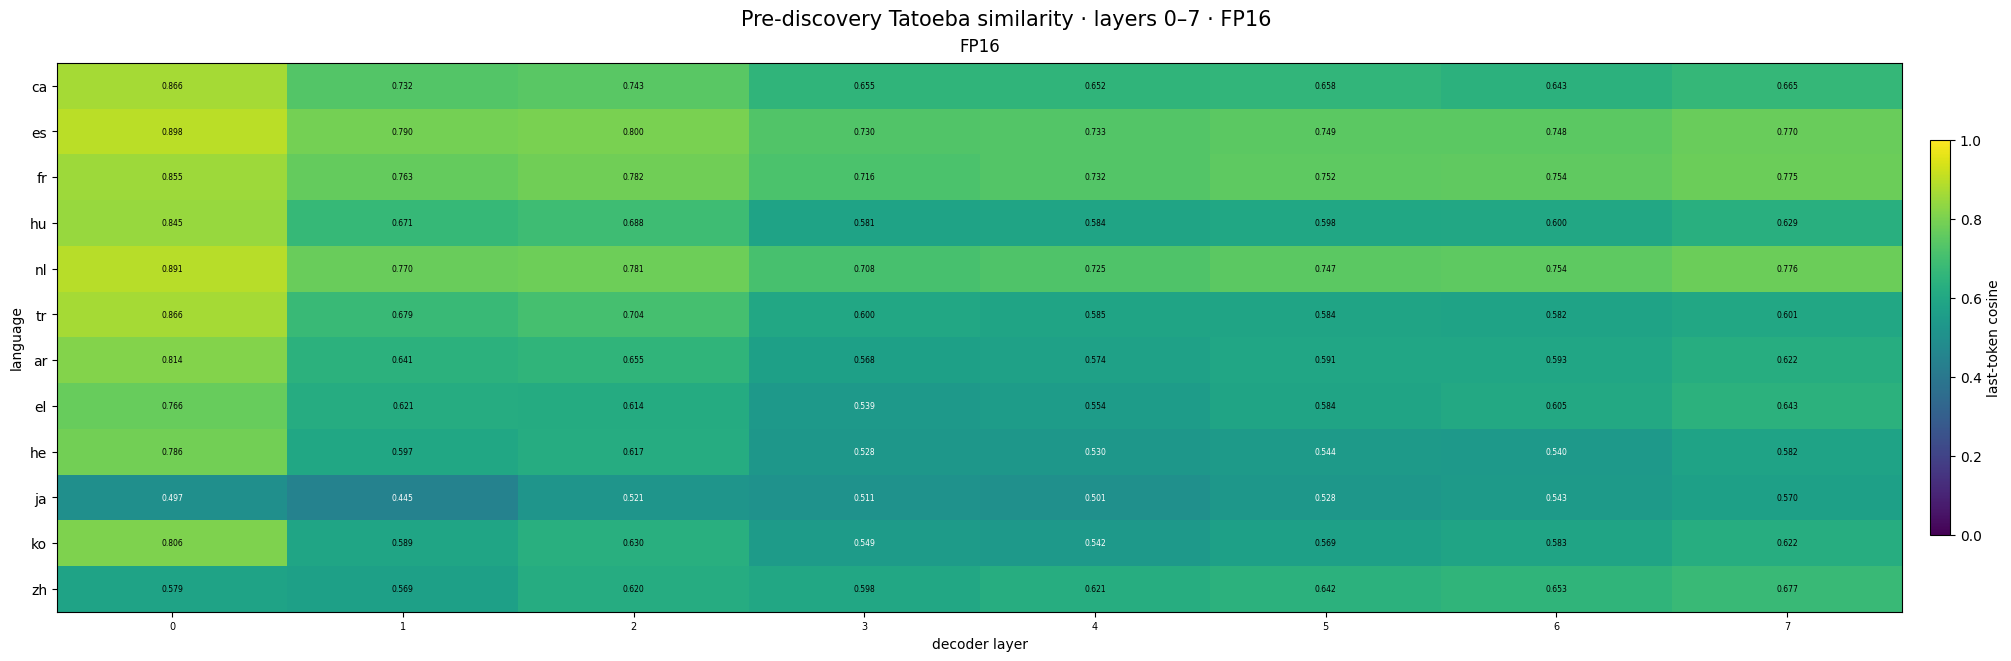

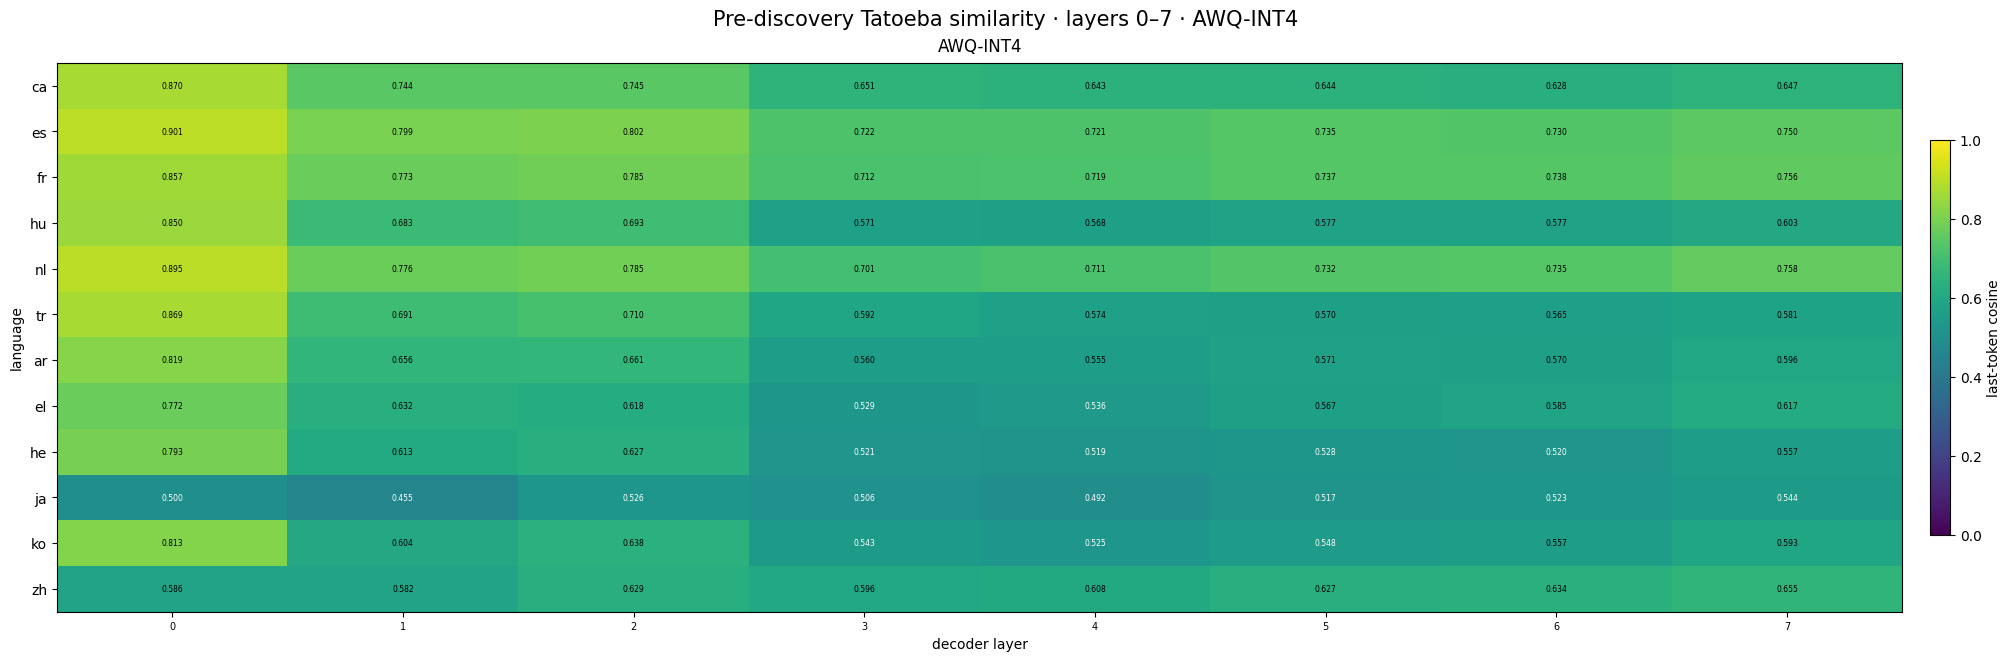

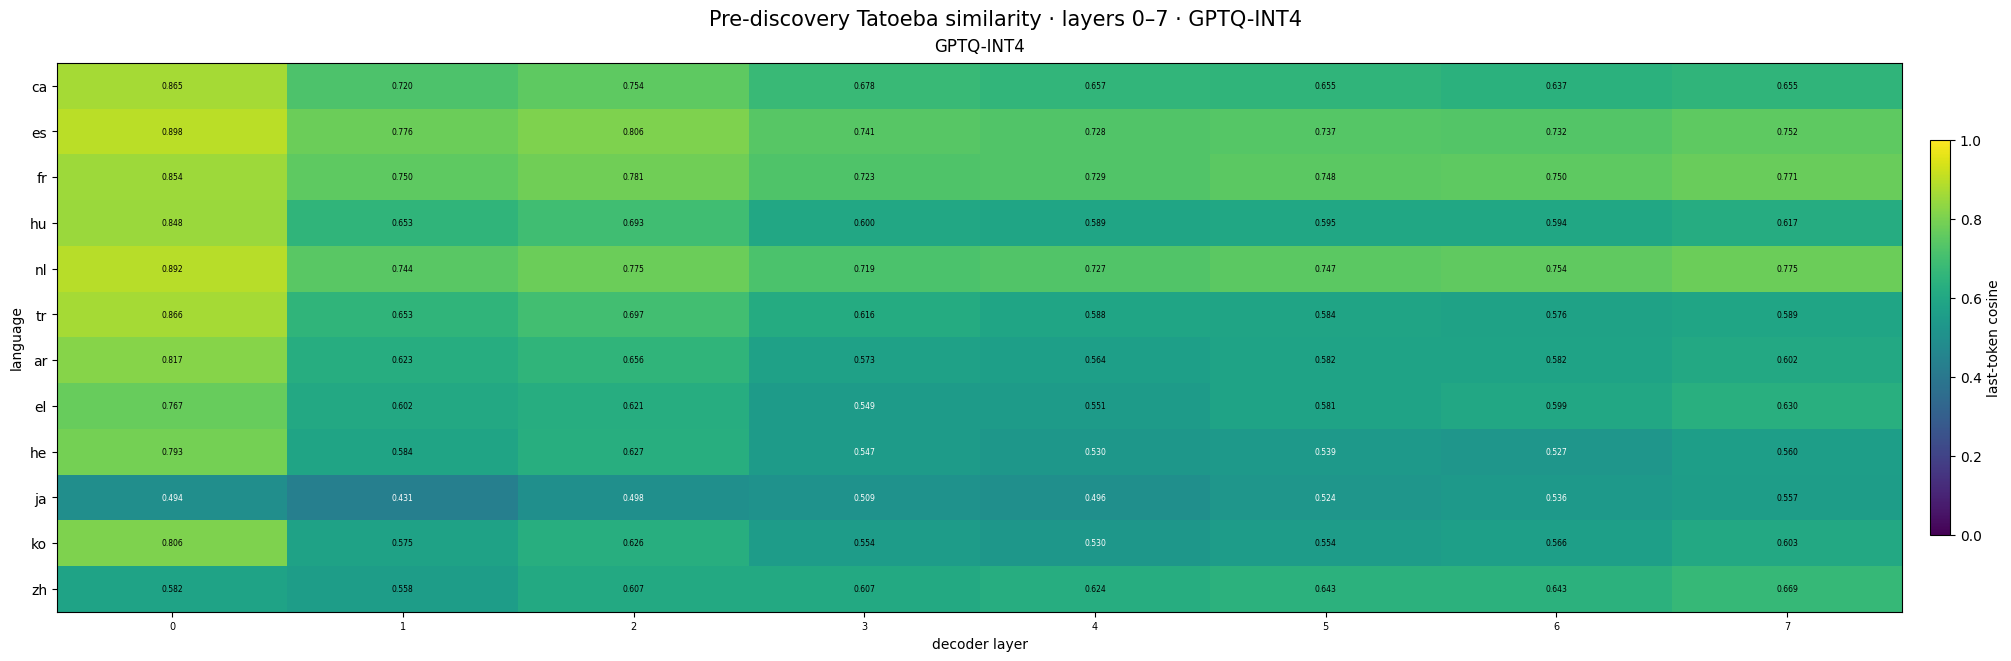

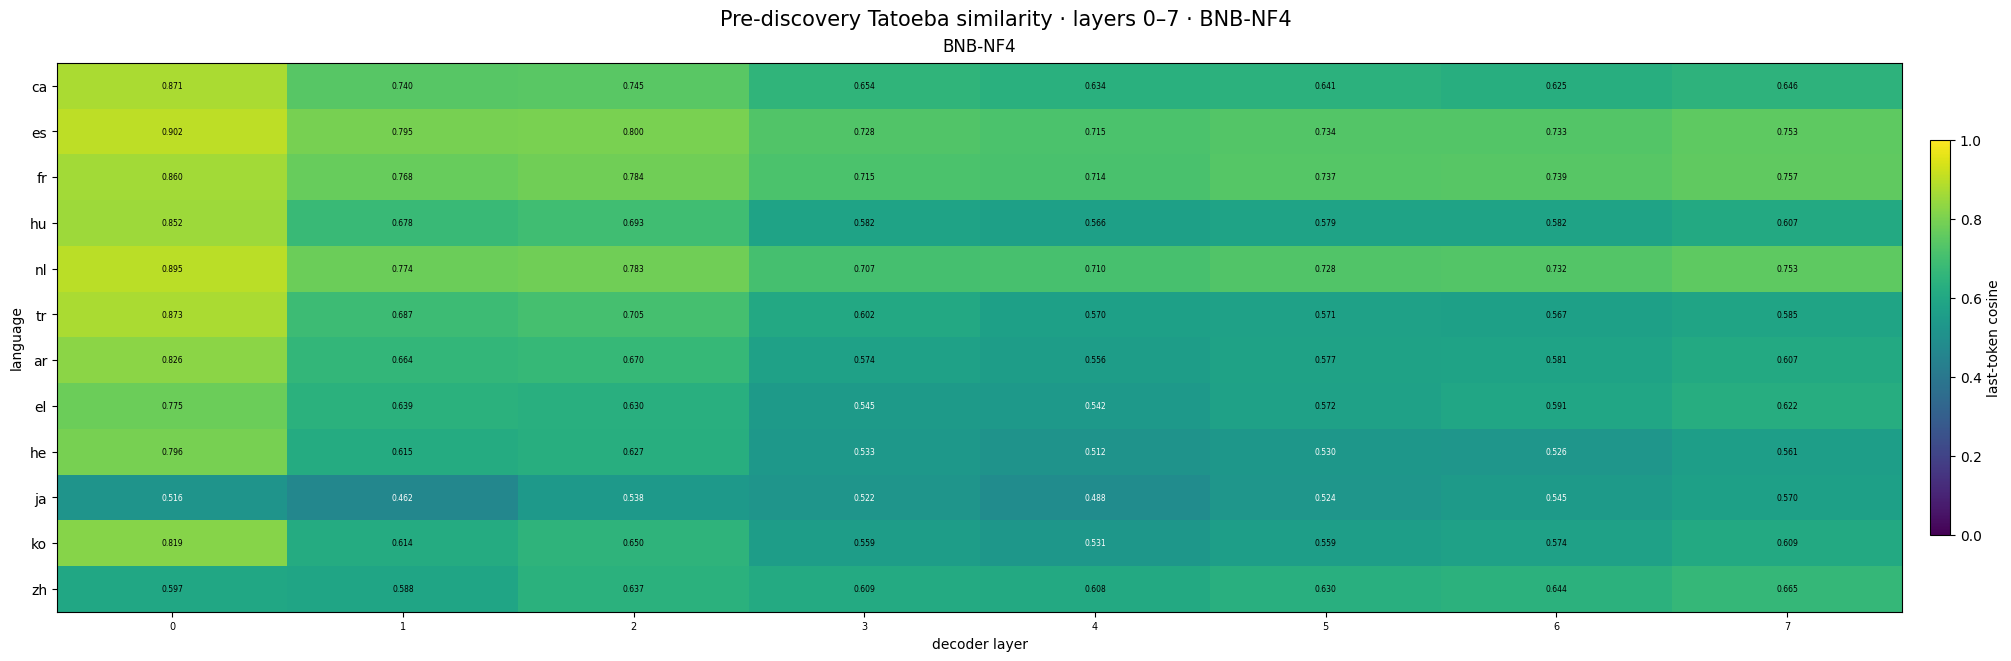

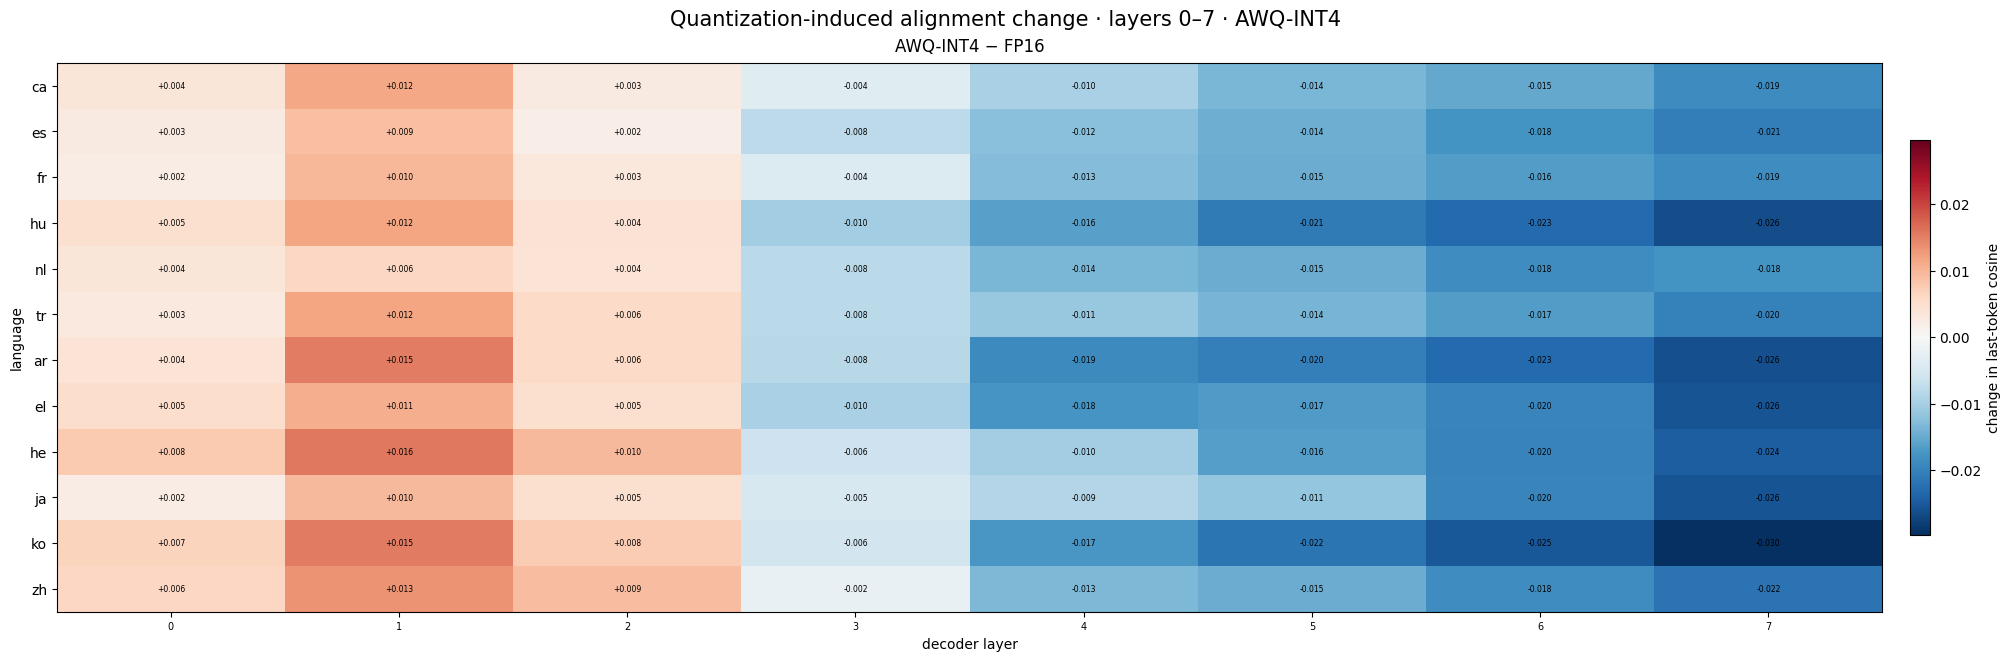

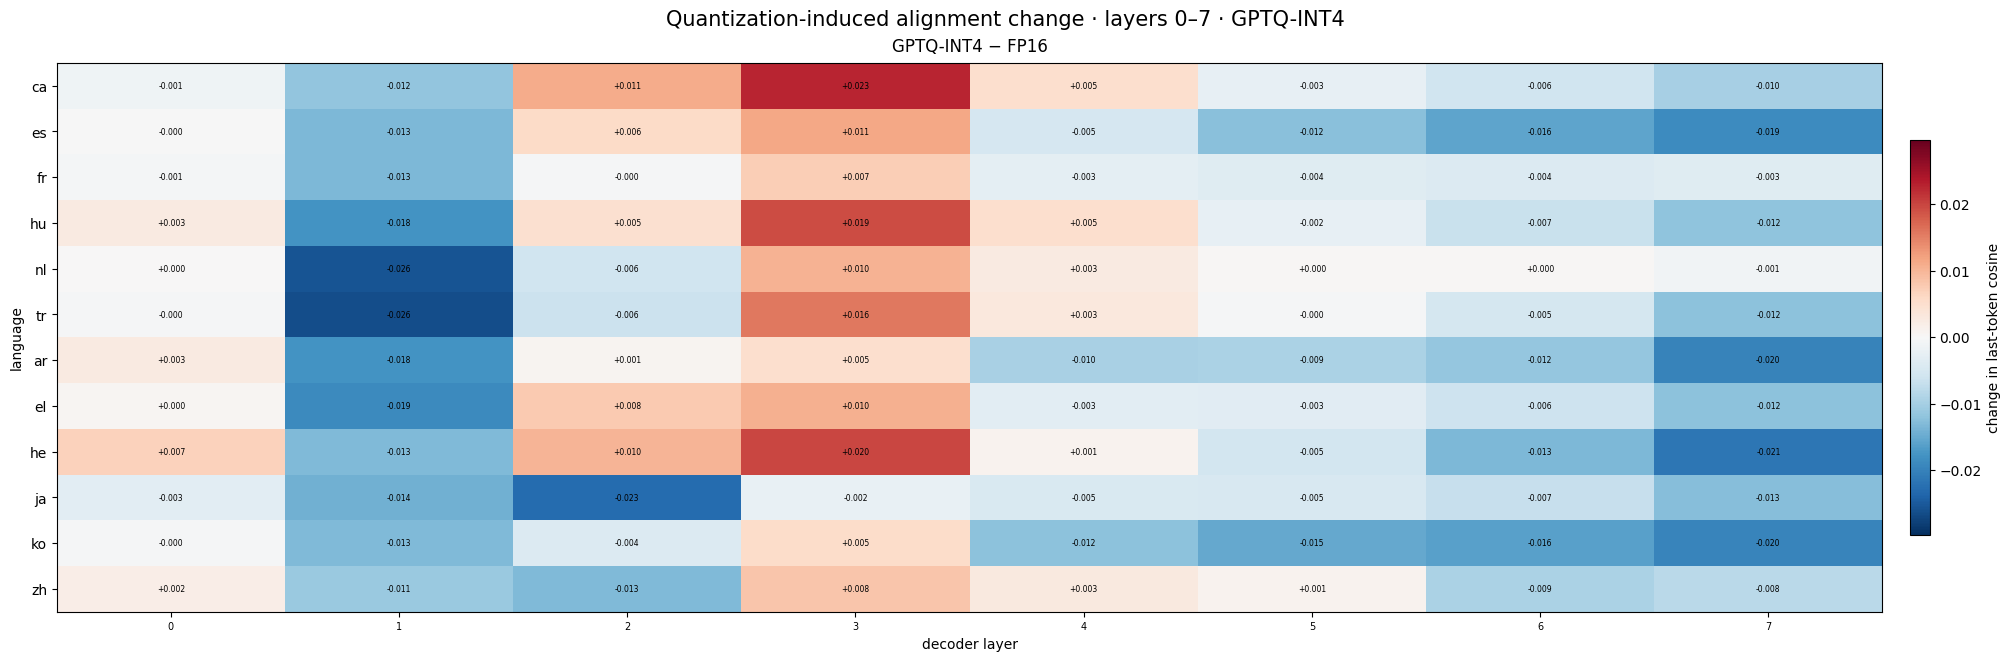

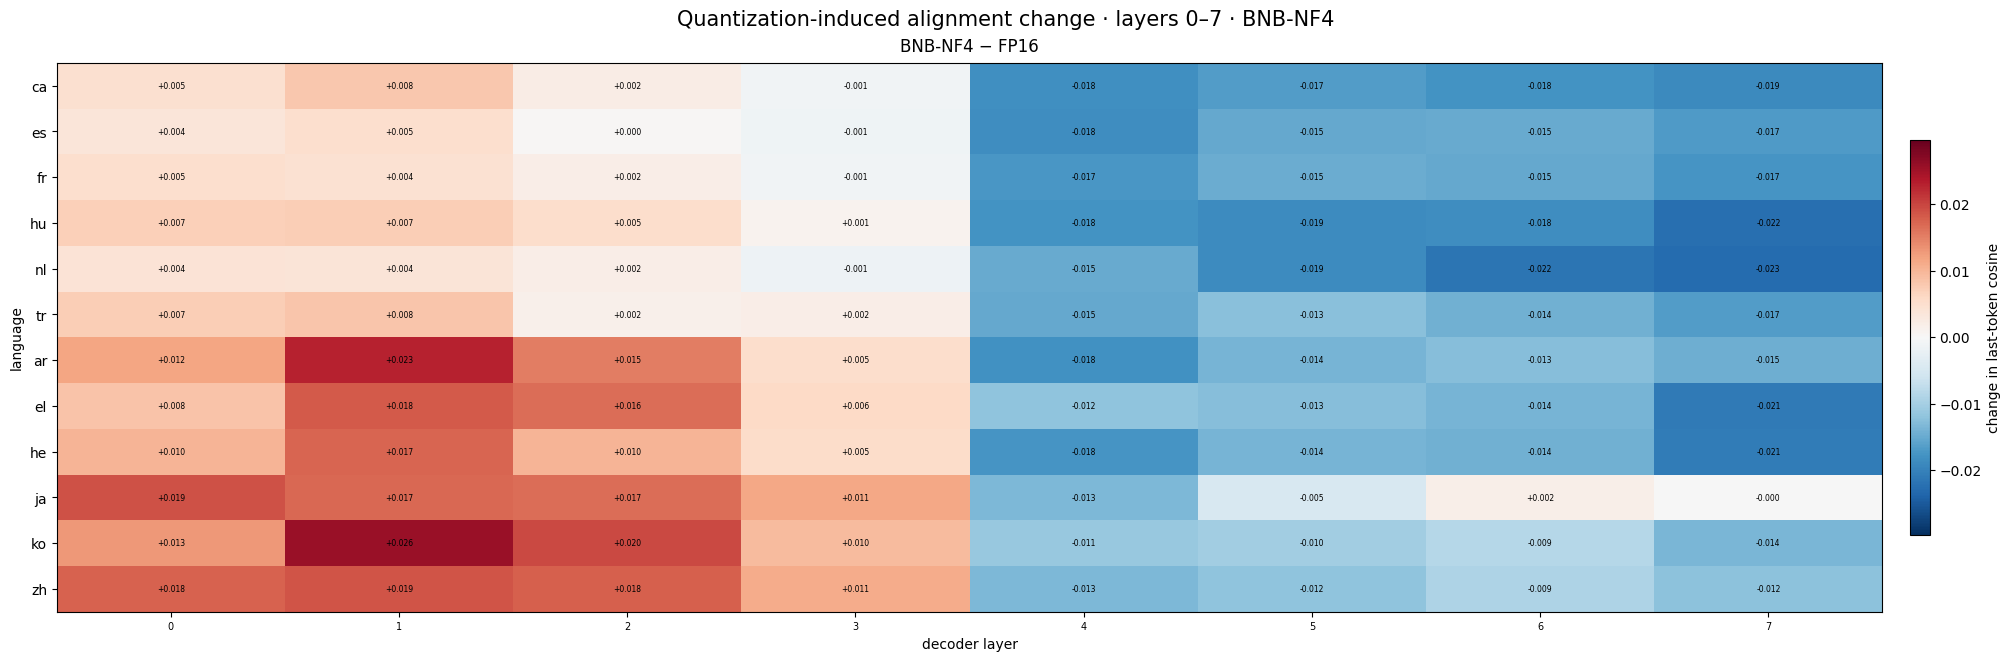

In [5]:
SIMILARITY_DEMO_LAYERS = list(range(8))
SIMILARITY_DEMO_KEYS = RECOVERY_KEYS[:min(SIMILARITY_DEMO_SAMPLES, len(RECOVERY_KEYS))]


@torch.no_grad()
def collect_last_token_demo_states(model, texts, layer_indices, batch_size=BATCH_SIZE):
    result = {layer: [] for layer in layer_indices}
    for start in tqdm(range(0, len(texts), batch_size), desc='similarity preview', leave=False):
        batch = encode_batch(
            TOKENIZER, texts[start:start + batch_size], input_device(model)
        )
        output = model(
            **batch, output_hidden_states=True, use_cache=False, return_dict=True
        )
        for layer in layer_indices:
            pooled = last_token_pool(output.hidden_states[layer + 1], batch['attention_mask'])
            result[layer].append(pooled.detach().float().cpu())
        del output, batch
    return {layer: torch.cat(parts, dim=0) for layer, parts in result.items()}


def demo_alignment_rows(model_name, model):
    rows = []
    for language in TARGET_LANGUAGES:
        target = collect_last_token_demo_states(
            model, prompts(language, SIMILARITY_DEMO_KEYS), SIMILARITY_DEMO_LAYERS
        )
        english = collect_last_token_demo_states(
            model, english_prompts_for(language, SIMILARITY_DEMO_KEYS),
            SIMILARITY_DEMO_LAYERS,
        )
        for layer in SIMILARITY_DEMO_LAYERS:
            per_pair = F.cosine_similarity(target[layer], english[layer], dim=-1)
            rows.append({
                'model': model_name,
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'layer': layer,
                'last_token_cosine': float(per_pair.mean()),
                'std_across_pairs': float(per_pair.std(unbiased=False)),
                'pairs': int(per_pair.numel()),
            })
        del target, english
    return rows


similarity_demo_rows = []
similarity_demo_failures = {}
for model_name in ['FP16'] + ACTIVE_QUANT_METHODS:
    try:
        demo_model = load_model(model_name)
        if SIMILARITY_DEMO_LAYERS is None:
            SIMILARITY_DEMO_LAYERS = list(range(len(decoder_layers(demo_model))))
            print('Similarity preview layers:', SIMILARITY_DEMO_LAYERS)
        similarity_demo_rows.extend(demo_alignment_rows(model_name, demo_model))
        del demo_model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    except Exception as exc:
        similarity_demo_failures[model_name] = repr(exc)
        print(f'Similarity preview failed for {model_name}: {exc}')
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

similarity_demo_df = pd.DataFrame(similarity_demo_rows)
if not similarity_demo_df.empty:
    fp_lookup = similarity_demo_df[similarity_demo_df.model == 'FP16'][
        ['language', 'layer', 'last_token_cosine']
    ].rename(columns={'last_token_cosine': 'fp16_last_token_cosine'})
    similarity_demo_df = similarity_demo_df.merge(
        fp_lookup, on=['language', 'layer'], how='left'
    )
    similarity_demo_df['change_from_fp16'] = (
        similarity_demo_df.last_token_cosine
        - similarity_demo_df.fp16_last_token_cosine
    )
    similarity_demo_df.to_csv(
        OUTPUT_DIR / 'pre_discovery_last_token_similarity_demo.csv', index=False
    )
    display(similarity_demo_df)

    models = similarity_demo_df.model.drop_duplicates().tolist()
    for model_name in models:
        fig, ax = plt.subplots(figsize=(20, 6.5), constrained_layout=True)
        part = similarity_demo_df[similarity_demo_df.model == model_name]
        matrix_df = part.pivot(
            index='language', columns='layer', values='last_token_cosine'
        ).reindex(index=LANGUAGE_DISPLAY_ORDER, columns=SIMILARITY_DEMO_LAYERS)
        matrix = matrix_df.to_numpy(dtype=float)
        image = ax.imshow(matrix, aspect='auto', cmap='viridis', vmin=0, vmax=1)
        ax.set_xticks(range(len(SIMILARITY_DEMO_LAYERS)), SIMILARITY_DEMO_LAYERS, fontsize=7)
        ax.set_yticks(range(len(LANGUAGE_DISPLAY_ORDER)), LANGUAGE_DISPLAY_ORDER)
        ax.set_xlabel('decoder layer')
        ax.set_ylabel('language')
        ax.set_title(model_name, fontsize=12, pad=8)
        for row in range(matrix.shape[0]):
            for col in range(matrix.shape[1]):
                ax.text(col, row, f'{matrix[row, col]:.3f}',
                        ha='center', va='center', fontsize=5.5,
                        color='white' if matrix[row, col] < .55 else 'black')
        fig.colorbar(image, ax=ax, shrink=.72, pad=.015, label='last-token cosine')
        fig.suptitle(
            f'Pre-discovery Tatoeba similarity · layers 0–7 · {model_name}', fontsize=15
        )
        plt.show()

    quant_demo = similarity_demo_df[similarity_demo_df.model != 'FP16']
    if not quant_demo.empty:
        models = quant_demo.model.drop_duplicates().tolist()
        limit = max(float(quant_demo.change_from_fp16.abs().max()), 1e-6)
        for model_name in models:
            fig, ax = plt.subplots(figsize=(20, 6.5), constrained_layout=True)
            part = quant_demo[quant_demo.model == model_name]
            matrix_df = part.pivot(
                index='language', columns='layer', values='change_from_fp16'
            ).reindex(index=LANGUAGE_DISPLAY_ORDER, columns=SIMILARITY_DEMO_LAYERS)
            matrix = matrix_df.to_numpy(dtype=float)
            image = ax.imshow(
                matrix, aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit
            )
            ax.set_xticks(range(len(SIMILARITY_DEMO_LAYERS)), SIMILARITY_DEMO_LAYERS, fontsize=7)
            ax.set_yticks(range(len(LANGUAGE_DISPLAY_ORDER)), LANGUAGE_DISPLAY_ORDER)
            ax.set_xlabel('decoder layer')
            ax.set_ylabel('language')
            ax.set_title(f'{model_name} − FP16', fontsize=12, pad=8)
            for row in range(matrix.shape[0]):
                for col in range(matrix.shape[1]):
                    ax.text(col, row, f'{matrix[row, col]:+.3f}',
                            ha='center', va='center', fontsize=5.5)
            fig.colorbar(image, ax=ax, shrink=.72, pad=.015,
                         label='change in last-token cosine')
            fig.suptitle(
                f'Quantization-induced alignment change · layers 0–7 · {model_name}',
                fontsize=15,
            )
            plt.show()

if similarity_demo_failures:
    print('Similarity preview unavailable models:', similarity_demo_failures)

## 3. 用 last-token 表示估计 FP16 shared centroid（Layer 0–7）

只对 decoder Layer 0–7 计算 shared centroid。每句英语和目标语言分别取最后一个非 padding token 的 block 输出，
先对配对的两个向量求均值，再对 1000 对 Tatoeba 平行句求均值。

In [6]:
@torch.no_grad()
def collect_post_block_hidden(model, texts, candidate_layers, batch_size=BATCH_SIZE):
    result = {layer: [] for layer in candidate_layers}
    for start in tqdm(
        range(0, len(texts), batch_size),
        desc='post-block hidden', leave=False,
    ):
        batch = encode_batch(
            TOKENIZER, texts[start:start + batch_size], input_device(model)
        )
        output = model(
            **batch, output_hidden_states=True,
            use_cache=False, return_dict=True,
        )
        stacked = torch.stack([
            last_token_pool(output.hidden_states[layer + 1], batch['attention_mask'])
            for layer in candidate_layers
        ], dim=0).detach().float().cpu()
        for local_layer, layer in enumerate(candidate_layers):
            result[layer].append(stacked[local_layer])
        del stacked, output, batch
    return {
        layer: torch.cat(parts, dim=0)
        for layer, parts in result.items()
    }


CANDIDATE_LAYERS = list(range(8))
RECOVERY_LAYERS = CANDIDATE_LAYERS.copy()
LAYER_SCOPE_TAG = 'layers_0_7'
centroid_path = OUTPUT_DIR / f'fp16_type1_centroids_{LAYER_SCOPE_TAG}_last_token.pt'

if centroid_path.exists() and not RECOMPUTE_CENTROIDS:
    centroid_payload = torch.load(centroid_path, map_location='cpu')
    if centroid_payload.get('token_representation') != 'last_nonpadding_token':
        raise RuntimeError('Centroid cache is not last-token based.')
    if centroid_payload['candidate_layers'] != CANDIDATE_LAYERS:
        raise RuntimeError(
            f'Centroid cache has {centroid_payload["candidate_layers"]}, '
            f'expected {CANDIDATE_LAYERS}.'
        )
    FP_CENTROIDS = centroid_payload['centroids']
    NUM_LAYERS = centroid_payload['num_layers']
    INTERMEDIATE_SIZE = centroid_payload['intermediate_size']
    print('Loaded:', centroid_path)
else:
    fp_model = load_model('FP16')
    NUM_LAYERS = len(decoder_layers(fp_model))
    INTERMEDIATE_SIZE = int(fp_model.config.intermediate_size)
    if max(CANDIDATE_LAYERS) >= NUM_LAYERS:
        raise ValueError(
            f'Model has {NUM_LAYERS} layers; cannot scan {CANDIDATE_LAYERS}.'
        )
    FP_CENTROIDS = {}
    for language in TARGET_LANGUAGES:
        en_hidden = collect_post_block_hidden(
            fp_model,
            english_prompts_for(language, CENTROID_KEYS),
            CANDIDATE_LAYERS,
        )
        target_hidden = collect_post_block_hidden(
            fp_model,
            prompts(language, CENTROID_KEYS),
            CANDIDATE_LAYERS,
        )
        FP_CENTROIDS[language] = {
            layer: ((en_hidden[layer] + target_hidden[layer]) / 2).mean(dim=0)
            for layer in CANDIDATE_LAYERS
        }
        del en_hidden, target_hidden
    torch.save({
        'centroids': FP_CENTROIDS,
        'token_representation': 'last_nonpadding_token',
        'candidate_layers': CANDIDATE_LAYERS,
        'num_layers': NUM_LAYERS,
        'intermediate_size': INTERMEDIATE_SIZE,
        'centroid_keys': CENTROID_KEYS,
        'dataset_tag': DATASET_TAG,
        'tatoeba_manifest': TATOEBA_MANIFEST,
    }, centroid_path)
    del fp_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print('Saved:', centroid_path)

print('Discovery layers:', CANDIDATE_LAYERS)
print('Recovery layers:', RECOVERY_LAYERS)
print('Intermediate size:', INTERMEDIATE_SIZE)

Loaded: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/last_nonpadding_token/fp16_type1_centroids_layers_0_7_last_token.pt
Discovery layers: [0, 1, 2, 3, 4, 5, 6, 7]
Recovery layers: [0, 1, 2, 3, 4, 5, 6, 7]
Intermediate size: 14336


## 4. 原论文 Transfer-Neuron score：仅 FP16、Layer 0–7

保持原论文 isolated-addition score：

\[
S_j^{paper}=\frac1N\sum_{s=1}^{N}[\cos(r_s+z_{s,j}W_j,C)-\cos(r_s,C)].
\]

每句取最后一个非 padding token，按原论文 isolated-addition score 计算 FP16 的 Layer 0–7 分数；
不再为三种量化模型重复寻找神经元。后续统一用 pooled FP16 Top-1% 阈值。

In [7]:
@torch.no_grad()
def collect_bridge_states(model, texts, candidate_layers, batch_size=BATCH_SIZE):
    """Collect only the r and z states needed by the original paper score."""
    layers = decoder_layers(model)
    collected = {name: {layer: [] for layer in candidate_layers} for name in ('r', 'z')}
    for start in tqdm(range(0, len(texts), batch_size), desc='paper-score states', leave=False):
        batch = encode_batch(TOKENIZER, texts[start:start + batch_size], input_device(model))
        attention_outputs, z_outputs, handles = {}, {}, []
        def select_last_token(value):
            return last_token_pool(value, batch['attention_mask']).detach()
        for layer_index in candidate_layers:
            def make_attn_hook(index):
                def hook(_module, _inputs, output):
                    attention_outputs[index] = select_last_token(output)
                return hook
            def make_down_pre(index):
                def hook(_module, inputs):
                    z_outputs[index] = select_last_token(inputs[0])
                return hook
            handles.append(layers[layer_index].self_attn.o_proj.register_forward_hook(make_attn_hook(layer_index)))
            handles.append(layers[layer_index].mlp.down_proj.register_forward_pre_hook(make_down_pre(layer_index)))
        try:
            output = model(**batch, output_hidden_states=True, use_cache=False, return_dict=True)
            for layer_index in candidate_layers:
                hs_pre = last_token_pool(output.hidden_states[layer_index], batch['attention_mask']).detach()
                collected['r'][layer_index].append((hs_pre + attention_outputs[layer_index]).to('cpu', dtype=torch.float16))
                collected['z'][layer_index].append(z_outputs[layer_index].to('cpu', dtype=torch.float16))
        finally:
            for handle in handles:
                handle.remove()
        del output, batch
    return {name: {layer: torch.cat(parts, dim=0) for layer, parts in by_layer.items()}
            for name, by_layer in collected.items()}

@torch.no_grad()
def paper_isolated_bridge_score(
    r_cpu, z_cpu, centroid_cpu, weight,
    sample_chunk=SCORE_SAMPLE_CHUNK,
):
    """Original-paper score with FP16 GPU GEMMs for every model.

    Weights and saved activations originate in FP16. They are cast on the current
    layer GPU to FP32 only for dot products, norms, cosine differences, and
    sample reduction.
    """
    device = weight.device
    compute_dtype = SCORE_COMPUTE_DTYPE
    weight_score = weight.to(device=device, dtype=compute_dtype)
    centroid = centroid_cpu.to(device=device, dtype=compute_dtype)
    eps = torch.finfo(compute_dtype).tiny
    centroid_norm = centroid.norm().clamp_min(eps)
    w_dot_c = centroid @ weight_score
    w_norm_sq = weight_score.square().sum(dim=0)
    score_sum = torch.zeros(
        weight_score.shape[1], device=device, dtype=torch.float32
    )
    sample_count = 0

    for start in range(0, r_cpu.shape[0], sample_chunk):
        stop = min(start + sample_chunk, r_cpu.shape[0])
        r = r_cpu[start:stop].to(
            device=device, dtype=compute_dtype, non_blocking=True
        )
        z = z_cpu[start:stop].to(
            device=device, dtype=compute_dtype, non_blocking=True
        )
        r_dot_c = r @ centroid
        r_norm_sq = r.square().sum(dim=1)
        base = r_dot_c / (
            r_norm_sq.sqrt().clamp_min(eps) * centroid_norm
        )
        r_dot_w = r @ weight_score
        numerator = r_dot_c[:, None] + z * w_dot_c[None, :]
        norm_sq = (
            r_norm_sq[:, None]
            + 2 * z * r_dot_w
            + z.square() * w_norm_sq[None, :]
        ).clamp_min(eps)
        delta = numerator / (norm_sq.sqrt() * centroid_norm) - base[:, None]
        score_sum += delta.float().sum(dim=0)
        sample_count += stop - start
        del r, z, r_dot_w, numerator, norm_sq, delta

    return (score_sum / sample_count).cpu()



def linear_runtime_device(module, fallback):
    parameter = next(module.parameters(recurse=True), None)
    if parameter is not None:
        return parameter.device
    buffer = next(module.buffers(recurse=True), None)
    if buffer is not None:
        return buffer.device
    for attribute in ('qweight', 'weight', 'scales', 'qzeros'):
        tensor = getattr(module, attribute, None)
        if torch.is_tensor(tensor):
            return tensor.device
    return fallback


@torch.no_grad()
def compute_paper_scores(model, representations, model_name):
    """Compute only the original paper's isolated-addition score."""
    layers = decoder_layers(model)
    score_lists = {language: [] for language in TARGET_LANGUAGES}
    for layer_index in tqdm(CANDIDATE_LAYERS, desc=f'paper score:{model_name}', leave=False):
        down_proj = layers[layer_index].mlp.down_proj
        if model_name == 'FP16':
            weight = dense_linear_weight(down_proj)
        else:
            weight = bridge_down_weight(model_name, layer_index, down_proj)
        score_device = linear_runtime_device(
            down_proj, fallback=input_device(model)
        )
        weight = weight.to(
            device=score_device,
            dtype=WEIGHT_ACTIVATION_DTYPE,
            non_blocking=True,
        )
        for language in TARGET_LANGUAGES:
            states = representations[language]
            score_lists[language].append(paper_isolated_bridge_score(
                states['r'][layer_index], states['z'][layer_index],
                FP_CENTROIDS[language][layer_index], weight,
            ))
        del weight
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return {language: torch.stack(values) for language, values in score_lists.items()}



FP_PAPER_SCORE_PATH = OUTPUT_DIR / (
    f'paper_scores_fp16_{LAYER_SCOPE_TAG}_last_token_fp32_score.pt'
)
if FP_PAPER_SCORE_PATH.exists() and not RECOMPUTE_SCORES:
    score_payload = torch.load(FP_PAPER_SCORE_PATH, map_location='cpu')
    if score_payload.get('token_representation') != 'last_nonpadding_token':
        raise RuntimeError('FP16 paper-score cache is not last-token based.')
    if score_payload.get('candidate_layers') != CANDIDATE_LAYERS:
        raise RuntimeError('FP16 paper-score cache has the wrong layer scope.')
    FP_PAPER_SCORES = score_payload['paper_scores']
    print('Loaded FP16 Layer 0–7 paper scores:', FP_PAPER_SCORE_PATH)
else:
    fp_model = load_model('FP16')
    fp_states = {
        language: collect_bridge_states(
            fp_model,
            prompts(language, DETECTION_KEYS),
            CANDIDATE_LAYERS,
        )
        for language in TARGET_LANGUAGES
    }
    FP_PAPER_SCORES = compute_paper_scores(fp_model, fp_states, 'FP16')
    torch.save({
        'paper_scores': FP_PAPER_SCORES,
        'token_representation': 'last_nonpadding_token',
        'detection_keys': DETECTION_KEYS,
        'candidate_layers': CANDIDATE_LAYERS,
        'dataset_tag': DATASET_TAG,
    }, FP_PAPER_SCORE_PATH)
    del fp_model, fp_states
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print('Saved FP16 Layer 0–7 paper scores:', FP_PAPER_SCORE_PATH)

PAPER_SCORES_BY_MODEL = {'FP16': FP_PAPER_SCORES}
MODEL_SCORES = PAPER_SCORES_BY_MODEL
MODEL_FAILURES = {}

Loaded FP16 Layer 0–7 paper scores: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/last_nonpadding_token/paper_scores_fp16_layers_0_7_last_token_fp32_score.pt


## 5. 唯一选择规则：Layer 0–7 pooled FP16 Top-1%

旧版 Top-500 / Top-1000 身份保留分析已删除。本 notebook 不重新识别量化模型
中的 Transfer Neurons。KLAR 部分会把所有目标语言、Layer 0–7 的 FP16 paper
scores 合并，用 pooled Top-1% 边界作为共享阈值。

In [8]:
# Intentionally no Top-500 / Top-1000 computation in this KLAR pilot.
print('Selection rule: FP16 pooled Top-1% over Layer 0–7 only.')

Selection rule: FP16 pooled Top-1% over Layer 0–7 only.


## 6. 跳过量化模型的神经元重新发现与旧功能分数统计

本实验直接干预由 FP16 固定识别出的 Top-1% 神经元。AWQ、GPTQ 和 BNB
只在 KLAR recovery 阶段加载，不再计算各自的全层 paper scores。

In [9]:
# Deliberately empty: no quantized-model Top-500/Top-1000 analysis.

## 7. 原论文 Transfer Neurons 的 recovery 区间

Recovery 只使用真实的 FP16 contribution trajectory 替换：

\[
\mathrm{MLP}^{patched}
=\mathrm{MLP}^{Q}
-\sum_{j\in S}z_j^QW_{down,j}^Q
+\sum_{j\in S}z_j^{FP}W_{down,j}^{FP}.
\]

本实验只干预 decoder Layer 0–7。神经元集合仅由原论文 FP16 paper score 的
pooled Top-1% 固定阈值决定；不运行 weight-only recovery。

In [10]:
RECOVERY_LAYERS = list(range(8))
if CANDIDATE_LAYERS != RECOVERY_LAYERS:
    raise RuntimeError(
        f'Discovery/recovery layer mismatch: '
        f'{CANDIDATE_LAYERS} vs {RECOVERY_LAYERS}'
    )
print('Recovery layers fixed to:', RECOVERY_LAYERS)

Recovery layers fixed to: [0, 1, 2, 3, 4, 5, 6, 7]


In [11]:
# Recovery quality is evaluated on the KLAR strict-failure subset below.

## 8. FP16 contribution-trajectory recovery

对 Layer 0–7 入选的原论文 Transfer Neurons，把量化模型当前 contribution
替换为 FP16 contribution。逐层数量匹配的随机神经元作为对照。

这是 notebook 中唯一的 recovery 方法；不计算 weight-only recovery。

In [12]:
@torch.no_grad()
def add_quant_down_weights_to_contribution_payload(q_model, payload, model_name):
    """Dequantize each Layer 0–7 down projection once per quantized model."""
    layers = decoder_layers(q_model)
    for layer_index in RECOVERY_LAYERS:
        dense = bridge_down_weight(
            model_name,
            layer_index,
            layers[layer_index].mlp.down_proj,
        )
        for language in TARGET_LANGUAGES:
            union = payload[language][layer_index]['union']
            if union.numel():
                payload[language][layer_index]['q_down'] = (
                    dense.index_select(1, union.to(dense.device))
                    .to('cpu', dtype=torch.float16)
                )
            else:
                payload[language][layer_index]['q_down'] = torch.empty(
                    (dense.shape[0], 0), dtype=torch.float16
                )
        del dense
    return payload

## 9. KLAR 严格失败样本：配置

`KLAR_DATA_DIR` 指向包含 `ar.json`、`en.json` 等原始 KLAR 文件的目录。
四份历史结果可以放在 `KLAR_RESULTS_DIR`，也可以和 notebook 放在同一目录；
下方解析器会依次搜索常见位置。

In [13]:
KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')
KLAR_RESULTS_DIR = Path('/root/autodl-tmp/analysis/klar')
KLAR_OUTPUT_DIR = OUTPUT_DIR / 'klar_layers0_7_top1pct_contribution_recovery'
KLAR_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

KLAR_RESULT_FILENAMES = {
    'FP16': 'llama3.1_fp16_result.json',
    'AWQ-INT4': 'llama3.1_awq-int4_result.json',
    'GPTQ-INT4': 'llama3.1_gptq-int4_result.json',
    'BNB-NF4': 'llama3.1_bnb-nf4_result.json',
}
KLAR_RESULT_SEARCH_DIRS = [
    KLAR_RESULTS_DIR,
    Path.cwd(),
    Path('/root/autodl-tmp'),
    Path('/root/autodl-tmp/data/klar'),
]

KLAR_SAMPLES_PER_LANGUAGE = 20
KLAR_Q_FORWARD_BATCH_SIZE = 2
KLAR_MAX_LENGTH = 512
KLAR_GENERATION_MAX_NEW_TOKENS = 8
KLAR_RANDOM_CONTROL_SEED = SEED + 9107
KLAR_RECOMPUTE_RECOVERY = True
KLAR_N_SHOT = 5
KLAR_ADD_GENERATION_PROMPT = True

def resolve_klar_result(filename):
    checked = []
    for directory in KLAR_RESULT_SEARCH_DIRS:
        candidate = directory / filename
        checked.append(str(candidate))
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f'Cannot find {filename}. Checked:\n' + '\n'.join(checked)
    )

KLAR_RESULT_PATHS = {
    model_name: resolve_klar_result(filename)
    for model_name, filename in KLAR_RESULT_FILENAMES.items()
}

print('KLAR raw data:', KLAR_DATA_DIR)
print('KLAR output:', KLAR_OUTPUT_DIR)
print('Recovery layers:', list(range(8)))
print('Selection: pooled FP16 last-token Top-1%')
print('Patched generation: greedy, max new tokens = 8')

KLAR raw data: /root/autodl-tmp/data/klar
KLAR output: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/last_nonpadding_token/klar_layers0_7_top1pct_contribution_recovery
Recovery layers: [0, 1, 2, 3, 4, 5, 6, 7]
Selection: pooled FP16 last-token Top-1%
Patched generation: greedy, max new tokens = 8


## 10. 重建原始五-shot prompt，并选择严格共同失败样本

样本选择精确到 `(language, record_id, template_id)`。三种量化方法使用完全
相同的样本，避免方法之间因为问题难度不同而无法直接比较。

In [14]:
def normalize_space(text):
    return ' '.join(str(text).split())


def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR language file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        relation_id = relation.get('relation_id', '')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace(
                        '<subject>', sample['subject']
                    ).split('<mask>')[0],
                    'answer': sample['object'],
                    'index': sample['index'],
                    'subject_en': (
                        sample['subject'] if language == 'en'
                        else sample.get('subject_en', '')
                    ),
                    'object_en': (
                        sample['object'] if language == 'en'
                        else sample.get('object_en', '')
                    ),
                    'relation_name': relation_name,
                    'relation_id': relation_id,
                    'template_id': template_id,
                })
            flattened.append(variants)
    if len(flattened) <= KLAR_N_SHOT:
        raise ValueError(f'{language}: insufficient KLAR facts')
    demonstrations = [
        flattened[i][i] for i in range(KLAR_N_SHOT)
    ]
    evaluation = flattened[KLAR_N_SHOT:]
    return demonstrations, evaluation


KLAR_RAW = {
    language: load_klar_language(language)
    for language in LANGUAGES
}
KLAR_RESULTS = {
    model_name: json.loads(path.read_text(encoding='utf-8'))
    for model_name, path in KLAR_RESULT_PATHS.items()
}


def result_prediction(model_name, language, record_id, template_id):
    record = KLAR_RESULTS[model_name][language]['records'][str(record_id)]
    prediction = record['predictions'][int(template_id)]
    if int(prediction['template_id']) != int(template_id):
        raise RuntimeError(
            f'Template mismatch for {model_name}/{language}/{record_id}/{template_id}'
        )
    return prediction


def prediction_correct(model_name, language, record_id, template_id):
    return bool(result_prediction(
        model_name, language, record_id, template_id
    )['correct'])


def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages


def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False,
        add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )


# Validate record ordering against the question saved by the old evaluation.
for language in LANGUAGES:
    _, evaluation = KLAR_RAW[language]
    records = KLAR_RESULTS['FP16'][language]['records']
    if len(evaluation) != len(records):
        raise RuntimeError(
            f'{language}: raw evaluation rows={len(evaluation)}, '
            f'result records={len(records)}'
        )
    for record_id in (0, len(evaluation) // 2, len(evaluation) - 1):
        stored = records[str(record_id)]['question']
        rebuilt = evaluation[record_id][0]['question']
        if normalize_space(stored) != normalize_space(rebuilt):
            raise RuntimeError(
                f'{language}: record ordering mismatch at {record_id}\n'
                f'stored={stored!r}\nrebuilt={rebuilt!r}'
            )


def strict_common_candidates(language):
    _, target_evaluation = KLAR_RAW[language]
    candidates = []
    for record_id, variants in enumerate(target_evaluation):
        for template_id, variant in enumerate(variants):
            key = (record_id, template_id)
            fp_en_ok = prediction_correct('FP16', 'en', *key)
            fp_target_ok = prediction_correct('FP16', language, *key)
            all_quant_transition_failures = all(
                prediction_correct(model_name, 'en', *key)
                and not prediction_correct(model_name, language, *key)
                for model_name in ACTIVE_QUANT_METHODS
            )
            if fp_en_ok and fp_target_ok and all_quant_transition_failures:
                candidates.append({
                    'language': language,
                    'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                    'record_id': record_id,
                    'template_id': template_id,
                    'relation_name': variant['relation_name'],
                    'relation_id': variant['relation_id'],
                    'fact_index': variant['index'],
                    'question': variant['question'],
                    'answer': variant['answer'],
                })
    return candidates


KLAR_CANDIDATES = {
    language: strict_common_candidates(language)
    for language in TARGET_LANGUAGES
}
candidate_count_df = pd.DataFrame([
    {
        'language': language,
        'script_group': LANGUAGE_SCRIPT_GROUPS[language],
        'strict_common_candidates': len(rows),
    }
    for language, rows in KLAR_CANDIDATES.items()
])
display(candidate_count_df)


def relation_stratified_sample(rows, n, seed):
    if len(rows) < n:
        raise ValueError(f'Only {len(rows)} candidates; requested {n}.')
    rng = random.Random(seed)
    grouped = defaultdict(list)
    for row in rows:
        grouped[row['relation_name']].append(row)
    for values in grouped.values():
        rng.shuffle(values)
    relation_order = list(grouped)
    rng.shuffle(relation_order)
    selected = []
    round_index = 0
    while len(selected) < n:
        added = False
        for relation in relation_order:
            values = grouped[relation]
            if round_index < len(values):
                selected.append(values[round_index])
                added = True
                if len(selected) == n:
                    break
        if not added:
            break
        round_index += 1
    if len(selected) != n:
        raise RuntimeError(f'Could select only {len(selected)} of {n}.')
    return selected


sampled_rows = []
for language_index, language in enumerate(TARGET_LANGUAGES):
    selected = relation_stratified_sample(
        KLAR_CANDIDATES[language],
        KLAR_SAMPLES_PER_LANGUAGE,
        SEED + 1009 * (language_index + 1),
    )
    for sample_index, row in enumerate(selected):
        row = dict(row)
        row['sample_id'] = f'{language}:{row["record_id"]}:{row["template_id"]}'
        row['language_sample_index'] = sample_index
        for model_name in ['FP16'] + ACTIVE_QUANT_METHODS:
            pred = result_prediction(
                model_name, language,
                row['record_id'], row['template_id'],
            )
            prefix = model_name.lower().replace('-', '_')
            row[f'{prefix}_prediction'] = pred['prediction']
            row[f'{prefix}_answer_mean_nll'] = pred.get('answer_mean_nll', np.nan)
        sampled_rows.append(row)

klar_sample_df = pd.DataFrame(sampled_rows)
klar_sample_df.to_csv(
    KLAR_OUTPUT_DIR / 'klar_strict_common_failure_sample.csv', index=False
)
display(klar_sample_df[[
    'sample_id', 'script_group', 'relation_name', 'question', 'answer'
]])
print('Selected:', len(klar_sample_df), 'exact prompts')
print(klar_sample_df.groupby(['script_group', 'language']).size())

,language,script_group,strict_common_candidates
0,ca,Latin,36
1,es,Latin,40
2,fr,Latin,75
3,hu,Latin,126
4,nl,Latin,37
5,tr,Latin,79
6,ar,Non-Latin,132
7,el,Non-Latin,107
8,he,Non-Latin,138
9,ja,Non-Latin,126


,sample_id,script_group,relation_name,question,answer
0,ca:889:4,Latin,relation_7,Quin lloc acull la seu de l’Germanwings? La re...,Colònia
1,ca:605:1,Latin,relation_3,Quin és el continent de Era víkinga? La respos...,Europa
2,ca:1281:3,Latin,relation_15,Quina religió practica Ilich Ramírez Sánchez? ...,islam
3,ca:700:0,Latin,relation_5,Quina empresa és el desenvolupador de New Tech...,Microsoft
4,ca:406:0,Latin,relation_2,Quin és el país o estat pel qual Nuuk és la ca...,Groenlàndia
...,...,...,...,...,...
235,zh:170:4,Non-Latin,relation_1,施瓦本行政区 的首都位于哪里？答案是：,奥格斯堡
236,zh:1217:1,Non-Latin,relation_15,比德 的宗教信仰是什么？答案是：,基督教
237,zh:986:0,Non-Latin,relation_9,十日谈 是在哪里创立的？答案是：,意大利
238,zh:441:1,Non-Latin,relation_3,澳大利亚 属于哪个大陆？答案是：,大洋洲


Selected: 240 exact prompts
script_group  language
Latin         ca          20
              es          20
              fr          20
              hu          20
              nl          20
              tr          20
Non-Latin     ar          20
              el          20
              he          20
              ja          20
              ko          20
              zh          20
dtype: int64


## 11. Single selection rule: pooled FP16 Top-1%

Pool the paper scores of all 12 target languages and decoder layers 0–7. The 99th-percentile score boundary is shared across languages; each language selects its own `(layer_index, neuron_index)` entries above that boundary. A layer-count-matched random control excludes the union of selected Transfer Neurons from **all languages**, not just the current language.


In [15]:
DOSE_SPECS = [
    {'label': '1.0%', 'slug': '1p0', 'rate': 0.010},
]
DOSE_LABELS = [spec['label'] for spec in DOSE_SPECS]
DOSE_SLUGS = [spec['slug'] for spec in DOSE_SPECS]
DOSE_RATE_BY_LABEL = {
    spec['label']: spec['rate'] for spec in DOSE_SPECS
}
RECOVERY_LAYERS = list(range(8))
KLAR_GENERATION_CONDITIONS_PER_BATCH = 3
if CANDIDATE_LAYERS != RECOVERY_LAYERS:
    raise RuntimeError(
        f'Discovery/recovery layer mismatch: '
        f'{CANDIDATE_LAYERS} vs {RECOVERY_LAYERS}'
    )

RECOVERY_NEURONS_PER_LANGUAGE = len(RECOVERY_LAYERS) * INTERMEDIATE_SIZE
POOLED_SCORE_COUNT = len(TARGET_LANGUAGES) * RECOVERY_NEURONS_PER_LANGUAGE
pooled_recovery_scores = torch.cat([
    FP_PAPER_SCORES[language].float().reshape(-1)
    for language in TARGET_LANGUAGES
])
if pooled_recovery_scores.numel() != POOLED_SCORE_COUNT:
    raise RuntimeError(
        f'Expected {POOLED_SCORE_COUNT} pooled scores, got '
        f'{pooled_recovery_scores.numel()}.'
    )

POOLED_THRESHOLDS = {}
for spec in DOSE_SPECS:
    target_count = int(math.ceil(POOLED_SCORE_COUNT * spec['rate']))
    POOLED_THRESHOLDS[spec['label']] = float(torch.topk(
        pooled_recovery_scores,
        k=target_count,
        largest=True,
        sorted=False,
    ).values.min())


def paper_masks_for_all_doses(language):
    scores = FP_PAPER_SCORES[language].float()
    result = {}
    for spec in DOSE_SPECS:
        result[spec['label']] = {
            layer_index: torch.nonzero(
                scores[local_layer] >= POOLED_THRESHOLDS[spec['label']],
                as_tuple=False,
            ).squeeze(1).cpu().long()
            for local_layer, layer_index in enumerate(RECOVERY_LAYERS)
        }
    for smaller, larger in zip(DOSE_LABELS[:-1], DOSE_LABELS[1:]):
        for layer_index in RECOVERY_LAYERS:
            small = set(result[smaller][layer_index].tolist())
            large = set(result[larger][layer_index].tolist())
            if not small.issubset(large):
                raise RuntimeError(
                    f'Non-nested paper masks: {language}, layer '
                    f'{layer_index}, {smaller}->{larger}'
                )
    return result


PAPER_MASKS_BY_DOSE = {
    language: paper_masks_for_all_doses(language)
    for language in TARGET_LANGUAGES
}
# Stable identity: decoder layer index plus MLP intermediate-channel index.
selected_id_rows = [
    {'language': language, 'layer': layer_index, 'neuron_index': int(neuron)}
    for language in TARGET_LANGUAGES
    for layer_index in RECOVERY_LAYERS
    for neuron in PAPER_MASKS_BY_DOSE[language]['1.0%'][layer_index].tolist()
]
pd.DataFrame(selected_id_rows).to_csv(
    KLAR_OUTPUT_DIR / 'transfer_neuron_ids_last_token_top1pct.csv', index=False
)


def random_masks_for_all_doses(language, seed):
    rng = np.random.default_rng(seed)
    result = {label: {} for label in DOSE_LABELS}
    for layer_index in RECOVERY_LAYERS:
        excluded = set().union(*[
            set(PAPER_MASKS_BY_DOSE[other]['1.0%'][layer_index].tolist())
            for other in TARGET_LANGUAGES
        ])
        pool = np.asarray([
            neuron for neuron in range(INTERMEDIATE_SIZE)
            if neuron not in excluded
        ], dtype=np.int64)
        permutation = rng.permutation(pool)
        previous = set()
        for label in DOSE_LABELS:
            count = int(
                PAPER_MASKS_BY_DOSE[language][label][layer_index].numel()
            )
            if count > len(pool):
                raise RuntimeError(
                    f'{language}/layer {layer_index}: random pool has {len(pool)} '
                    f'neurons but {count} are required.'
                )
            selected = torch.as_tensor(
                permutation[:count].copy(), dtype=torch.long
            )
            current = set(selected.tolist())
            if not previous.issubset(current):
                raise RuntimeError('Random dose masks are not nested.')
            previous = current
            result[label][layer_index] = selected
    return result


RANDOM_MASKS_BY_DOSE = {
    language: random_masks_for_all_doses(
        language,
        KLAR_RANDOM_CONTROL_SEED + 313 * (language_index + 1),
    )
    for language_index, language in enumerate(TARGET_LANGUAGES)
}

RECOVERY_MASKS = {language: {} for language in TARGET_LANGUAGES}
RECOVERY_CONDITION_NAMES = []
for spec in DOSE_SPECS:
    paper_name = f"paper_{spec['slug']}"
    random_name = f"random_{spec['slug']}"
    RECOVERY_CONDITION_NAMES.extend([paper_name, random_name])
    for language in TARGET_LANGUAGES:
        RECOVERY_MASKS[language][paper_name] = (
            PAPER_MASKS_BY_DOSE[language][spec['label']]
        )
        RECOVERY_MASKS[language][random_name] = (
            RANDOM_MASKS_BY_DOSE[language][spec['label']]
        )

LANGUAGE_DOSE_NEURON_COUNTS = {language: {} for language in TARGET_LANGUAGES}
count_rows, layer_count_rows = [], []
for language in TARGET_LANGUAGES:
    for spec in DOSE_SPECS:
        label = spec['label']
        paper = PAPER_MASKS_BY_DOSE[language][label]
        random_mask = RANDOM_MASKS_BY_DOSE[language][label]
        paper_count = sum(int(x.numel()) for x in paper.values())
        random_count = sum(int(x.numel()) for x in random_mask.values())
        if paper_count != random_count:
            raise RuntimeError(
                f'{language}/{label}: paper={paper_count}, '
                f'random={random_count}'
            )
        LANGUAGE_DOSE_NEURON_COUNTS[language][label] = paper_count
        count_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'dose': label,
            'dose_rate': spec['rate'],
            'paper_neurons': paper_count,
            'density': paper_count / RECOVERY_NEURONS_PER_LANGUAGE,
            'shared_fp16_threshold': POOLED_THRESHOLDS[label],
        })
        for layer_index in RECOVERY_LAYERS:
            layer_count_rows.append({
                'language': language,
                'script_group': LANGUAGE_SCRIPT_GROUPS[language],
                'dose': label,
                'dose_rate': spec['rate'],
                'layer': layer_index,
                'paper_neurons': int(paper[layer_index].numel()),
            })

dose_count_df = pd.DataFrame(count_rows)
dose_layer_count_df = pd.DataFrame(layer_count_rows)
dose_count_df.to_csv(
    KLAR_OUTPUT_DIR / 'fp16_pooled_top1pct_counts.csv', index=False
)
dose_layer_count_df.to_csv(
    KLAR_OUTPUT_DIR / 'fp16_pooled_top1pct_layer_counts.csv', index=False
)
display(pd.DataFrame([
    {
        'dose': spec['label'],
        'rate': spec['rate'],
        'pooled_score_count': POOLED_SCORE_COUNT,
        'target_memberships': int(math.ceil(
            POOLED_SCORE_COUNT * spec['rate']
        )),
        'shared_fp16_threshold': POOLED_THRESHOLDS[spec['label']],
    }
    for spec in DOSE_SPECS
]))
display(dose_count_df.pivot(
    index='language', columns='dose', values='paper_neurons'
).reindex(index=LANGUAGE_DISPLAY_ORDER, columns=DOSE_LABELS))

,dose,rate,pooled_score_count,target_memberships,shared_fp16_threshold
0,1.0%,0.01,1376256,13763,0.000192


dose,1.0%
language,
ca,1045
es,965
fr,1015
hu,1165
nl,1009
tr,1116
ar,1119
el,1120
he,1271


## 12. 原论文式 last-token 消融（先于量化恢复）

原论文的干预不是把 FP16 contribution 加回量化模型，而是将所选神经元在**目标语言句子最后一个 token** 的 MLP `act_fn` 输出设为零；英语句子保持原样。这里在 held-out Tatoeba 平行句上分别测试 pooled Top-1% Transfer Neurons 和逐层同数量 random（random 排除所有语言的入选神经元）。**主指标**是在同一目标语言输入上比较原始 FP16 与置零后的下一 token logits：$D_{KL}(P_{base}\|P_{zero})$；同时统计最高概率 token 是否改变，并以逐层英语—目标语言 cosine similarity 作辅助指标。KL 越大表示输出分布受干预越大，但只有显著大于匹配 random 时才支持 Transfer Neurons 的特异性作用。这个步骤只用 FP16 模型；下一节才是 KLAR 上的量化 contribution 恢复。


INFO:accelerate.utils.modeling:We will use 90% of the memory on device 0 for storing the model, and 10% for the buffer to avoid OOM. You can set `max_memory` in to a higher value to use more memory (at your own risk).


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

paper-style last-token ablation:   0%|          | 0/2 [00:00<?, ?it/s]

paper-style last-token ablation:   0%|          | 0/2 [00:00<?, ?it/s]

paper-style last-token ablation:   0%|          | 0/2 [00:00<?, ?it/s]

paper-style last-token ablation:   0%|          | 0/2 [00:00<?, ?it/s]

... (43 outputs left out)

paper-style last-token ablation:   0%|          | 0/2 [00:00<?, ?it/s]

,language,script_group,layer,pairs,baseline_cosine,paper_zero_cosine,random_zero_cosine,paper_minus_baseline,random_minus_baseline,paper_minus_random
0,ca,Latin,0,32,0.866394,0.757319,0.865776,-0.109075,-0.000618,-0.108457
1,ca,Latin,1,32,0.731962,0.509028,0.730904,-0.222934,-0.001059,-0.221876
2,ca,Latin,2,32,0.742700,0.510434,0.742557,-0.232265,-0.000142,-0.232123
3,ca,Latin,3,32,0.655074,0.317863,0.655077,-0.337211,0.000003,-0.337214
4,ca,Latin,4,32,0.652364,0.308060,0.652892,-0.344304,0.000528,-0.344832
...,...,...,...,...,...,...,...,...,...,...
91,zh,Non-Latin,3,32,0.598376,0.362508,0.600750,-0.235868,0.002374,-0.238242
92,zh,Non-Latin,4,32,0.621439,0.319887,0.622036,-0.301552,0.000597,-0.302149
93,zh,Non-Latin,5,32,0.642237,0.269986,0.641603,-0.372251,-0.000634,-0.371617
94,zh,Non-Latin,6,32,0.652773,0.177900,0.651863,-0.474873,-0.000910,-0.473963


,language,script_group,pairs,paper_mean_kl,paper_median_kl,random_mean_kl,random_median_kl,mean_paired_kl_excess,paper_top1_flip_rate,random_top1_flip_rate,paired_excess_ci_low,paired_excess_ci_high,fraction_paper_kl_gt_random
0,ar,Non-Latin,32,0.498531,0.326393,0.001050,0.000921,0.497481,0.62500,0.03125,0.370555,0.658273,1.0
1,ca,Latin,32,1.120056,0.528889,0.001040,0.000496,1.119016,0.68750,0.00000,0.665540,1.700836,1.0
2,el,Non-Latin,32,0.917123,0.471963,0.001583,0.000853,0.915540,0.65625,0.00000,0.583967,1.311846,1.0
3,es,Latin,32,0.766748,0.705144,0.001063,0.000485,0.765684,0.65625,0.03125,0.589311,0.949505,1.0
4,fr,Latin,32,0.581672,0.363463,0.001706,0.000653,0.579966,0.56250,0.00000,0.412769,0.772105,1.0
5,he,Non-Latin,32,0.991374,0.556085,0.001237,0.000753,0.990138,0.68750,0.06250,0.640083,1.468864,1.0
6,hu,Latin,32,0.759399,0.440406,0.003201,0.000499,0.756198,0.53125,0.03125,0.486847,1.063833,1.0
7,ja,Non-Latin,32,1.070183,0.918849,0.002775,0.001854,1.067408,0.78125,0.09375,0.886342,1.263417,1.0
8,ko,Non-Latin,32,0.593512,0.371254,0.001461,0.000950,0.592050,0.50000,0.12500,0.410249,0.795292,1.0
9,nl,Latin,32,0.720042,0.355905,0.000911,0.000589,0.719131,0.56250,0.00000,0.459150,1.032463,1.0


KL samples: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/last_nonpadding_token/klar_layers0_7_top1pct_contribution_recovery/paper_style_last_token_top1pct_logit_kl_samples.csv
KL summary: /root/autodl-tmp/analysis/type1_bridge_neuron_stats_paper_tatoeba_1000_12targets_latin_nonlatin/last_nonpadding_token/klar_layers0_7_top1pct_contribution_recovery/paper_style_last_token_top1pct_logit_kl_summary.csv


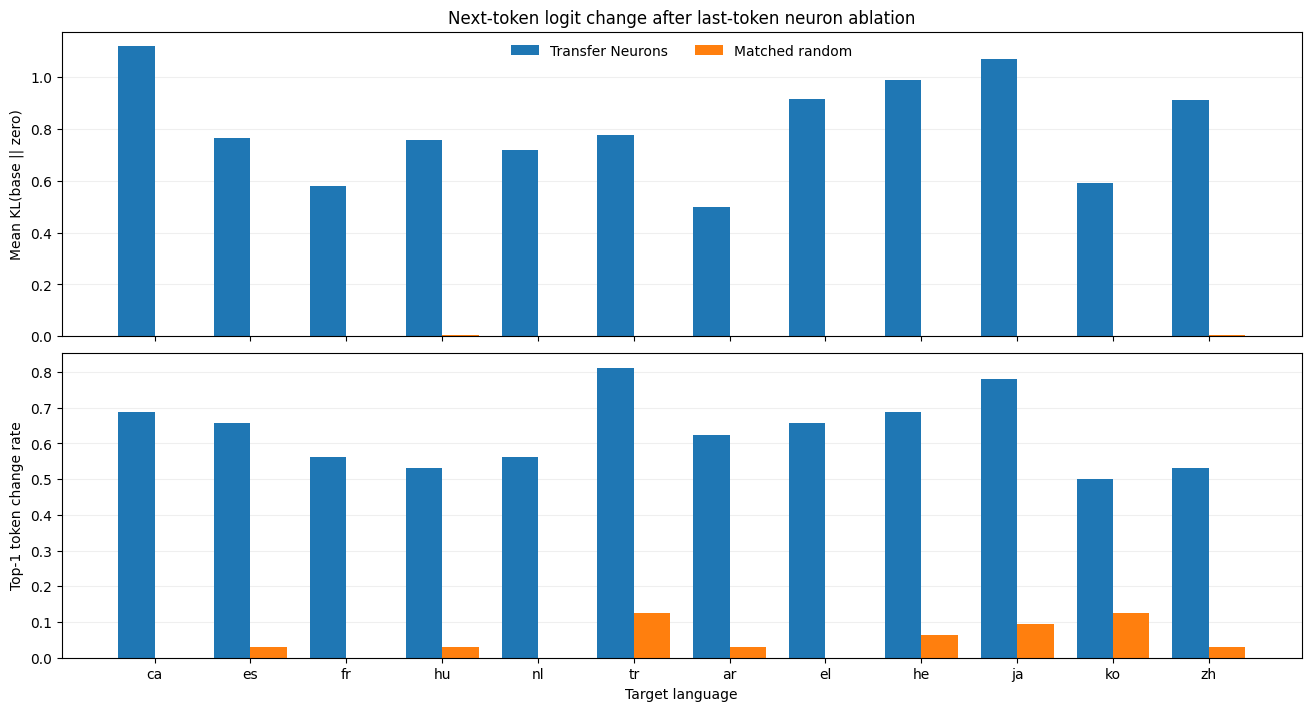

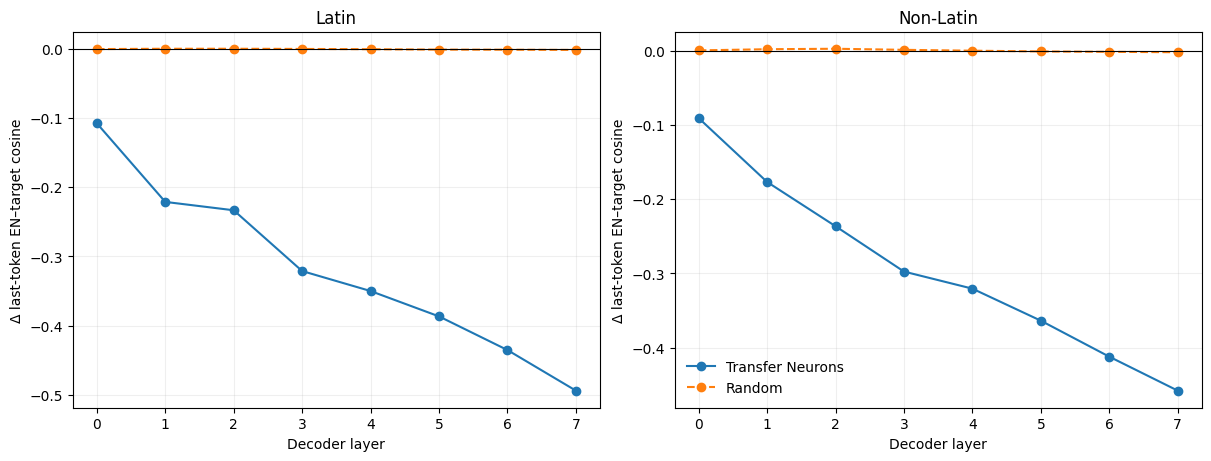

In [16]:
PAPER_ABLATION_SAMPLES = 32
PAPER_ABLATION_KEYS = RECOVERY_KEYS[:min(PAPER_ABLATION_SAMPLES, len(RECOVERY_KEYS))]
if not PAPER_ABLATION_KEYS:
    raise ValueError('Held-out Tatoeba pairs are required for paper-style ablation.')


@torch.no_grad()
def collect_last_token_states_with_ablation(
    model, texts, selected_by_layer=None, batch_size=BATCH_SIZE,
):
    """Cumulative layer outputs; zero act_fn channels only at each last valid token."""
    layers = decoder_layers(model)
    result = {layer: [] for layer in RECOVERY_LAYERS}
    result['logits'] = []
    for start in tqdm(range(0, len(texts), batch_size),
                      desc='paper-style last-token ablation', leave=False):
        batch = encode_batch(
            TOKENIZER, texts[start:start + batch_size], input_device(model)
        )
        attention_mask = batch['attention_mask']
        if (~attention_mask.bool().any(dim=1)).any():
            raise ValueError('A sentence contains no valid tokens.')
        last_positions = (
            attention_mask.shape[1] - 1
            - attention_mask.flip(1).long().argmax(dim=1)
        )
        handles = []
        if selected_by_layer is not None:
            for layer_index in RECOVERY_LAYERS:
                selected = selected_by_layer[layer_index].long()
                if selected.numel() == 0:
                    continue

                def make_zero_hook(neurons):
                    def hook(_module, _inputs, output):
                        patched = output.clone()
                        rows = torch.arange(patched.shape[0], device=patched.device)
                        positions = last_positions.to(patched.device)
                        channels = neurons.to(patched.device)
                        patched[rows[:, None], positions[:, None],
                                channels[None, :]] = 0
                        return patched
                    return hook

                handles.append(
                    layers[layer_index].mlp.act_fn.register_forward_hook(
                        make_zero_hook(selected)
                    )
                )
        try:
            output = model(
                **batch, output_hidden_states=True,
                use_cache=False, return_dict=True,
            )
            for layer_index in RECOVERY_LAYERS:
                states = last_token_pool(
                    output.hidden_states[layer_index + 1], attention_mask
                )
                result[layer_index].append(states.detach().float().cpu())
            next_token_logits = last_token_pool(output.logits, attention_mask)
            result['logits'].append(next_token_logits.detach().float().cpu())
        finally:
            for handle in handles:
                handle.remove()
        del output, batch
    return {
        layer: torch.cat(parts, dim=0)
        for layer, parts in result.items()
    }


PAPER_ABLATION_PATH = (
    KLAR_OUTPUT_DIR / 'paper_style_last_token_top1pct_ablation.csv'
)
PAPER_ABLATION_KL_SAMPLE_PATH = (
    KLAR_OUTPUT_DIR / 'paper_style_last_token_top1pct_logit_kl_samples.csv'
)
PAPER_ABLATION_KL_SUMMARY_PATH = (
    KLAR_OUTPUT_DIR / 'paper_style_last_token_top1pct_logit_kl_summary.csv'
)
fp_ablation_model = load_model('FP16')
ablation_rows = []
ablation_kl_rows = []
for language in TARGET_LANGUAGES:
    english_texts = english_prompts_for(language, PAPER_ABLATION_KEYS)
    target_texts = prompts(language, PAPER_ABLATION_KEYS)
    english_states = collect_last_token_states_with_ablation(
        fp_ablation_model, english_texts
    )
    target_baseline = collect_last_token_states_with_ablation(
        fp_ablation_model, target_texts
    )
    target_paper = collect_last_token_states_with_ablation(
        fp_ablation_model, target_texts,
        PAPER_MASKS_BY_DOSE[language]['1.0%'],
    )
    target_random = collect_last_token_states_with_ablation(
        fp_ablation_model, target_texts,
        RANDOM_MASKS_BY_DOSE[language]['1.0%'],
    )
    # Compare next-token distributions for the same target-language prompt.
    base_logp = F.log_softmax(target_baseline['logits'], dim=-1)
    base_p = base_logp.exp()
    paper_logp = F.log_softmax(target_paper['logits'], dim=-1)
    random_logp = F.log_softmax(target_random['logits'], dim=-1)
    paper_kl = (base_p * (base_logp - paper_logp)).sum(dim=-1).clamp_min(0)
    random_kl = (base_p * (base_logp - random_logp)).sum(dim=-1).clamp_min(0)
    base_top1 = target_baseline['logits'].argmax(dim=-1)
    paper_flip = target_paper['logits'].argmax(dim=-1) != base_top1
    random_flip = target_random['logits'].argmax(dim=-1) != base_top1
    for sample_index, sample_key in enumerate(PAPER_ABLATION_KEYS):
        ablation_kl_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'sample_key': str(sample_key),
            'paper_kl_base_to_zero': float(paper_kl[sample_index]),
            'random_kl_base_to_zero': float(random_kl[sample_index]),
            'paper_minus_random_kl': float(paper_kl[sample_index] - random_kl[sample_index]),
            'paper_top1_changed': bool(paper_flip[sample_index]),
            'random_top1_changed': bool(random_flip[sample_index]),
        })
    for layer_index in RECOVERY_LAYERS:
        en = english_states[layer_index]
        baseline_cos = F.cosine_similarity(
            en, target_baseline[layer_index], dim=-1
        )
        paper_cos = F.cosine_similarity(en, target_paper[layer_index], dim=-1)
        random_cos = F.cosine_similarity(en, target_random[layer_index], dim=-1)
        ablation_rows.append({
            'language': language,
            'script_group': LANGUAGE_SCRIPT_GROUPS[language],
            'layer': layer_index,
            'pairs': len(PAPER_ABLATION_KEYS),
            'baseline_cosine': float(baseline_cos.mean()),
            'paper_zero_cosine': float(paper_cos.mean()),
            'random_zero_cosine': float(random_cos.mean()),
            'paper_minus_baseline': float((paper_cos - baseline_cos).mean()),
            'random_minus_baseline': float((random_cos - baseline_cos).mean()),
            'paper_minus_random': float((paper_cos - random_cos).mean()),
        })
    del english_states, target_baseline, target_paper, target_random

del fp_ablation_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

PAPER_ABLATION_DF = pd.DataFrame(ablation_rows)
PAPER_ABLATION_DF.to_csv(PAPER_ABLATION_PATH, index=False)
display(PAPER_ABLATION_DF)

PAPER_ABLATION_KL_SAMPLES_DF = pd.DataFrame(ablation_kl_rows)
PAPER_ABLATION_KL_SAMPLES_DF.to_csv(PAPER_ABLATION_KL_SAMPLE_PATH, index=False)
PAPER_ABLATION_KL_SUMMARY_DF = (
    PAPER_ABLATION_KL_SAMPLES_DF.groupby(['language', 'script_group'], as_index=False)
    .agg(pairs=('paper_kl_base_to_zero', 'size'),
         paper_mean_kl=('paper_kl_base_to_zero', 'mean'),
         paper_median_kl=('paper_kl_base_to_zero', 'median'),
         random_mean_kl=('random_kl_base_to_zero', 'mean'),
         random_median_kl=('random_kl_base_to_zero', 'median'),
         mean_paired_kl_excess=('paper_minus_random_kl', 'mean'),
         paper_top1_flip_rate=('paper_top1_changed', 'mean'),
         random_top1_flip_rate=('random_top1_changed', 'mean'))
)
# Paired bootstrap: the same sentences are used for paper and random ablations.
bootstrap_rng = np.random.default_rng(SEED + 1701)
bootstrap_rows = []
for language, part in PAPER_ABLATION_KL_SAMPLES_DF.groupby('language'):
    paired = part.paper_minus_random_kl.to_numpy(dtype=np.float64)
    draws = bootstrap_rng.integers(0, len(paired), size=(2000, len(paired)))
    bootstrap_means = paired[draws].mean(axis=1)
    lower, upper = np.quantile(bootstrap_means, [.025, .975])
    bootstrap_rows.append({
        'language': language,
        'paired_excess_ci_low': lower,
        'paired_excess_ci_high': upper,
        'fraction_paper_kl_gt_random': float((paired > 0).mean()),
    })
PAPER_ABLATION_KL_SUMMARY_DF = PAPER_ABLATION_KL_SUMMARY_DF.merge(
    pd.DataFrame(bootstrap_rows), on='language', validate='one_to_one'
)
PAPER_ABLATION_KL_SUMMARY_DF.to_csv(PAPER_ABLATION_KL_SUMMARY_PATH, index=False)
display(PAPER_ABLATION_KL_SUMMARY_DF)
print('KL samples:', PAPER_ABLATION_KL_SAMPLE_PATH)
print('KL summary:', PAPER_ABLATION_KL_SUMMARY_PATH)

ordered_kl = PAPER_ABLATION_KL_SUMMARY_DF.set_index('language').reindex(
    [lang for lang in LANGUAGE_DISPLAY_ORDER if lang in TARGET_LANGUAGES]
)
x = np.arange(len(ordered_kl))
fig_kl, (ax_kl, ax_flip) = plt.subplots(2, 1, figsize=(13, 7),
                                         sharex=True, constrained_layout=True)
width = .38
ax_kl.bar(x - width / 2, ordered_kl.paper_mean_kl, width, label='Transfer Neurons')
ax_kl.bar(x + width / 2, ordered_kl.random_mean_kl, width, label='Matched random')
ax_kl.set_ylabel('Mean KL(base || zero)')
ax_kl.set_title('Next-token logit change after last-token neuron ablation')
ax_kl.legend(frameon=False, ncol=2)
ax_flip.bar(x - width / 2, ordered_kl.paper_top1_flip_rate, width)
ax_flip.bar(x + width / 2, ordered_kl.random_top1_flip_rate, width)
ax_flip.set_ylabel('Top-1 token change rate')
ax_flip.set_xlabel('Target language')
ax_flip.set_xticks(x, ordered_kl.index)
for ax in (ax_kl, ax_flip):
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for axis, group in zip(axes, SCRIPT_GROUP_ORDER):
    part = PAPER_ABLATION_DF[PAPER_ABLATION_DF.script_group == group]
    means = part.groupby('layer')[
        ['paper_minus_baseline', 'random_minus_baseline']
    ].mean()
    axis.plot(means.index, means.paper_minus_baseline,
              marker='o', label='Transfer Neurons')
    axis.plot(means.index, means.random_minus_baseline,
              marker='o', linestyle='--', label='Random')
    axis.axhline(0, color='black', linewidth=.8)
    axis.set_title(group)
    axis.set_xlabel('Decoder layer')
    axis.set_ylabel('Δ last-token EN–target cosine')
    axis.grid(alpha=.2)
axes[1].legend(frameon=False)
plt.show()


## 12. Quantized baseline and Top-1% contribution replacement

The saved quantized outputs identify the strict failure pool. We rerun each quantized model under the same eight-token greedy setting, then replace the selected MLP-neuron contribution at layers 0–7 with its FP16 counterpart on every forward step:

$$\mathrm{MLP}^{patched}=\mathrm{MLP}^{Q}-\sum_{j\in S} z_j^Q W_{down,j}^{Q}+\sum_{j\in S}z_j^{FP}W_{down,j}^{FP}.$$

The random condition has the same per-layer count and does not intersect the Top-1% Transfer Neurons of any target language. Full generated answers are compared against gold answers.


In [17]:
def selected_rows_for_language(language):
    return klar_sample_df[
        klar_sample_df.language == language
    ].sort_values('language_sample_index').to_dict('records')


def encode_klar_prompt_batch(rows):
    """Left-pad prompts for manual greedy decoding."""
    sequences = []
    for row in rows:
        prompt = klar_prompt_text(
            row['language'], int(row['record_id']), int(row['template_id'])
        )
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if len(ids) + KLAR_GENERATION_MAX_NEW_TOKENS > KLAR_MAX_LENGTH:
            raise ValueError(
                f'{row["sample_id"]}: prompt + generation exceeds '
                f'KLAR_MAX_LENGTH={KLAR_MAX_LENGTH}'
            )
        sequences.append(ids)
    width = max(len(ids) for ids in sequences)
    pad_id = int(TOKENIZER.pad_token_id)
    input_ids = torch.full((len(rows), width), pad_id, dtype=torch.long)
    attention_mask = torch.zeros((len(rows), width), dtype=torch.long)
    for index, ids in enumerate(sequences):
        input_ids[index, width - len(ids):] = torch.tensor(ids, dtype=torch.long)
        attention_mask[index, width - len(ids):] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


def normalize_generated_answer(text):
    import unicodedata
    normalized = unicodedata.normalize('NFKC', str(text))
    normalized = ' '.join(normalized.strip().split()).casefold()
    return normalized.strip(' \\t\\n\\r.,;:!?。；：！？"\'`“”‘’()[]{}')


def patched_answer_correct(text, gold_answer):
    return (
        normalize_generated_answer(text)
        == normalize_generated_answer(gold_answer)
    )


def decode_new_tokens(generated_token_rows):
    texts = []
    eos_id = TOKENIZER.eos_token_id
    pad_id = TOKENIZER.pad_token_id
    for token_ids in generated_token_rows:
        kept = []
        for token_id in token_ids:
            token_id = int(token_id)
            if eos_id is not None and token_id == int(eos_id):
                break
            if pad_id is not None and token_id == int(pad_id):
                continue
            kept.append(token_id)
        texts.append(TOKENIZER.decode(kept, skip_special_tokens=True))
    return texts


@torch.no_grad()
def build_recovery_contribution_payload(fp_model):
    layers = decoder_layers(fp_model)
    payload = {language: {} for language in TARGET_LANGUAGES}
    for layer_index in RECOVERY_LAYERS:
        fp_down_full = dense_linear_weight(
            layers[layer_index].mlp.down_proj
        )
        for language in TARGET_LANGUAGES:
            selected = torch.unique(torch.cat([
                PAPER_MASKS[language][layer_index],
                RANDOM_MASKS[language][layer_index],
            ])).sort().values
            lookup = torch.full(
                (INTERMEDIATE_SIZE,), -1, dtype=torch.long
            )
            lookup[selected] = torch.arange(selected.numel(), dtype=torch.long)
            payload[language][layer_index] = {
                'union': selected.cpu(),
                'lookup': lookup,
                'fp_down': fp_down_full.index_select(
                    1, selected.to(fp_down_full.device)
                ).to('cpu', dtype=torch.float16),
            }
        del fp_down_full
    return payload


def down_output_device(module, fallback=None):
    parameter = next(module.parameters(recurse=True), None)
    if parameter is not None:
        return parameter.device
    buffer = next(module.buffers(recurse=True), None)
    if buffer is not None:
        return buffer.device
    for attribute in ('qweight', 'weight', 'scales', 'qzeros'):
        tensor = getattr(module, attribute, None)
        if torch.is_tensor(tensor):
            return tensor.device
    if fallback is not None:
        return fallback
    raise RuntimeError(f'Cannot determine device for {module.__class__.__name__}')


def materialize_language_payload(q_model, language_payload):
    layers = decoder_layers(q_model)
    result = {}
    for layer_index in RECOVERY_LAYERS:
        device = down_output_device(
            layers[layer_index].mlp.down_proj,
            fallback=input_device(q_model),
        )
        source = language_payload[layer_index]
        result[layer_index] = {
            'union': source['union'],
            'lookup': source['lookup'],
            'fp_down': source['fp_down'].to(
                device=device, non_blocking=True
            ),
            'q_down': source['q_down'].to(
                device=device, non_blocking=True
            ),
        }
    return result


@torch.no_grad()
def capture_fp_prefix_z(fp_model, input_ids, attention_mask, language_payload):
    layers = decoder_layers(fp_model)
    captured, handles = {}, []
    for layer_index in RECOVERY_LAYERS:
        selected = language_payload[layer_index]['union']
        def make_hook(index, neuron_indices):
            def hook(_module, inputs):
                captured[index] = inputs[0].index_select(
                    -1, neuron_indices.to(inputs[0].device)
                ).detach()
            return hook
        handles.append(
            layers[layer_index].mlp.down_proj.register_forward_pre_hook(
                make_hook(layer_index, selected)
            )
        )
    try:
        fp_model(
            input_ids=input_ids.to(input_device(fp_model)),
            attention_mask=attention_mask.to(input_device(fp_model)),
            use_cache=False, return_dict=True,
        )
    finally:
        for handle in handles:
            handle.remove()
    return captured


@torch.no_grad()
def patched_prefix_next_ids(
    q_model, input_ids, attention_mask, selected_by_layer,
    language_payload, fp_z_by_layer,
):
    layers = decoder_layers(q_model)
    current_qz, handles = {}, []
    for layer_index in RECOVERY_LAYERS:
        selected = selected_by_layer[layer_index].long()
        positions = language_payload[layer_index]['lookup'][selected].long()
        if (positions < 0).any():
            raise RuntimeError(
                f'Missing payload neuron at layer {layer_index}'
            )

        def make_pre(index, neuron_indices):
            def hook(_module, inputs):
                current_qz[index] = inputs[0].index_select(
                    -1, neuron_indices.to(inputs[0].device)
                )
            return hook

        def make_out(index, payload_positions):
            def hook(_module, _inputs, output):
                if not payload_positions.numel():
                    return output
                device, dtype = output.device, output.dtype
                pos = payload_positions.to(device=device)
                fp_z = fp_z_by_layer[index].index_select(
                    -1, pos.to(fp_z_by_layer[index].device)
                ).to(device=device, dtype=dtype)
                q_z = current_qz[index].to(dtype=dtype)
                payload_layer = language_payload[index]
                fp_down = payload_layer['fp_down'].index_select(
                    1, pos
                ).to(dtype=dtype)
                q_down = payload_layer['q_down'].index_select(
                    1, pos
                ).to(dtype=dtype)
                return (
                    output
                    - F.linear(q_z, q_down)
                    + F.linear(fp_z, fp_down)
                )
            return hook

        handles.append(
            layers[layer_index].mlp.down_proj.register_forward_pre_hook(
                make_pre(layer_index, selected)
            )
        )
        handles.append(
            layers[layer_index].mlp.down_proj.register_forward_hook(
                make_out(layer_index, positions)
            )
        )
    try:
        output = q_model(
            input_ids=input_ids.to(input_device(q_model)),
            attention_mask=attention_mask.to(input_device(q_model)),
            use_cache=False, return_dict=True,
        )
        return output.logits[:, -1, :].float().argmax(dim=-1).cpu()
    finally:
        for handle in handles:
            handle.remove()


@torch.no_grad()
def generate_quantized_baseline(q_model, prompt_batch):
    """Re-run the original quantized model with the same greedy 8-token setup."""
    ids = prompt_batch['input_ids'].to(input_device(q_model))
    mask = prompt_batch['attention_mask'].to(input_device(q_model))
    generated = [[] for _ in range(ids.shape[0])]
    finished = torch.zeros(ids.shape[0], dtype=torch.bool, device=ids.device)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        output = q_model(
            input_ids=ids,
            attention_mask=mask,
            use_cache=False,
            return_dict=True,
        )
        next_ids = output.logits[:, -1, :].float().argmax(dim=-1)
        del output
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(
            was_finished, torch.full_like(next_ids, pad_id), next_ids
        )
        append_mask = (~was_finished).long()
        ids = torch.cat([ids, append_ids[:, None]], dim=1)
        mask = torch.cat([mask, append_mask[:, None]], dim=1)
        if bool(finished.all()):
            break
    return decode_new_tokens(generated)


@torch.no_grad()
def generate_with_contribution_recovery(
    fp_model, q_model, prompt_batch, selected_by_layer,
    fp_language_payload, q_language_payload,
):
    ids = prompt_batch['input_ids'].cpu()
    mask = prompt_batch['attention_mask'].cpu()
    generated = [[] for _ in range(ids.shape[0])]
    finished = torch.zeros(ids.shape[0], dtype=torch.bool)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        fp_z = capture_fp_prefix_z(
            fp_model, ids, mask, fp_language_payload
        )
        next_ids = patched_prefix_next_ids(
            q_model=q_model,
            input_ids=ids,
            attention_mask=mask,
            selected_by_layer=selected_by_layer,
            language_payload=q_language_payload,
            fp_z_by_layer=fp_z,
        )
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(
            was_finished, torch.full_like(next_ids, pad_id), next_ids
        )
        append_mask = (~was_finished).long()
        ids = torch.cat([ids, append_ids[:, None]], dim=1)
        mask = torch.cat([mask, append_mask[:, None]], dim=1)
        del fp_z
        if bool(finished.all()):
            break
    return decode_new_tokens(generated)


@torch.no_grad()
def build_multidose_contribution_payload(fp_model):
    layers = decoder_layers(fp_model)
    payload = {language: {} for language in TARGET_LANGUAGES}
    for layer_index in RECOVERY_LAYERS:
        fp_down_full = dense_linear_weight(
            layers[layer_index].mlp.down_proj
        )
        for language in TARGET_LANGUAGES:
            pieces = [
                RECOVERY_MASKS[language][condition][layer_index]
                for condition in RECOVERY_CONDITION_NAMES
            ]
            union = torch.unique(torch.cat(pieces)).sort().values
            lookup = torch.full(
                (INTERMEDIATE_SIZE,), -1, dtype=torch.long
            )
            lookup[union] = torch.arange(union.numel(), dtype=torch.long)
            payload[language][layer_index] = {
                'union': union.cpu(),
                'lookup': lookup,
                'fp_down': fp_down_full.index_select(
                    1, union.to(fp_down_full.device)
                ).to('cpu', dtype=torch.float16),
            }
        del fp_down_full
    return payload


@torch.no_grad()
def patched_prefix_next_ids_conditions(
    q_model, input_ids, attention_mask, condition_names,
    masks_by_condition, language_payload, fp_z_by_layer,
    base_batch_size,
):
    layers = decoder_layers(q_model)
    current_qz, handles = {}, []
    for layer_index in RECOVERY_LAYERS:
        selected_by_condition = [
            masks_by_condition[name][layer_index].long()
            for name in condition_names
        ]
        positions_by_condition = [
            language_payload[layer_index]['lookup'][selected].long()
            for selected in selected_by_condition
        ]
        if any((positions < 0).any() for positions in positions_by_condition):
            raise RuntimeError(
                f'Missing multidose payload neuron at layer {layer_index}'
            )

        def make_pre(index, selections):
            def hook(_module, inputs):
                full_z = inputs[0]
                for condition_index, selected in enumerate(selections):
                    start = condition_index * base_batch_size
                    stop = start + base_batch_size
                    current_qz[(index, condition_index)] = full_z[
                        start:stop
                    ].index_select(-1, selected.to(full_z.device))
            return hook

        def make_out(index, selections, positions):
            def hook(_module, _inputs, output):
                patched = output.clone()
                payload_layer = language_payload[index]
                for condition_index, (selected, payload_pos) in enumerate(
                    zip(selections, positions)
                ):
                    if not selected.numel():
                        continue
                    start = condition_index * base_batch_size
                    stop = start + base_batch_size
                    device, dtype = output.device, output.dtype
                    pos = payload_pos.to(device=device)
                    fp_z = fp_z_by_layer[index][start:stop].index_select(
                        -1, pos.to(fp_z_by_layer[index].device)
                    ).to(device=device, dtype=dtype)
                    q_z = current_qz[(index, condition_index)].to(dtype=dtype)
                    fp_down = payload_layer['fp_down'].index_select(
                        1, pos
                    ).to(dtype=dtype)
                    q_down = payload_layer['q_down'].index_select(
                        1, pos
                    ).to(dtype=dtype)
                    patched[start:stop] = (
                        output[start:stop]
                        - F.linear(q_z, q_down)
                        + F.linear(fp_z, fp_down)
                    )
                return patched
            return hook

        handles.append(
            layers[layer_index].mlp.down_proj.register_forward_pre_hook(
                make_pre(layer_index, selected_by_condition)
            )
        )
        handles.append(
            layers[layer_index].mlp.down_proj.register_forward_hook(
                make_out(
                    layer_index,
                    selected_by_condition,
                    positions_by_condition,
                )
            )
        )
    try:
        output = q_model(
            input_ids=input_ids.to(input_device(q_model)),
            attention_mask=attention_mask.to(input_device(q_model)),
            use_cache=False, return_dict=True,
        )
        return output.logits[:, -1, :].float().argmax(dim=-1).cpu()
    finally:
        for handle in handles:
            handle.remove()


@torch.no_grad()
def generate_recovery_conditions(
    fp_model, q_model, prompt_batch, condition_names,
    masks_by_condition, fp_language_payload, q_language_payload,
):
    condition_count = len(condition_names)
    base_batch_size = prompt_batch['input_ids'].shape[0]
    ids = prompt_batch['input_ids'].repeat(condition_count, 1).cpu()
    mask = prompt_batch['attention_mask'].repeat(condition_count, 1).cpu()
    total = ids.shape[0]
    generated = [[] for _ in range(total)]
    finished = torch.zeros(total, dtype=torch.bool)
    eos_id = TOKENIZER.eos_token_id
    pad_id = int(TOKENIZER.pad_token_id)

    for _ in range(KLAR_GENERATION_MAX_NEW_TOKENS):
        fp_z = capture_fp_prefix_z(
            fp_model, ids, mask, fp_language_payload
        )
        next_ids = patched_prefix_next_ids_conditions(
            q_model=q_model,
            input_ids=ids,
            attention_mask=mask,
            condition_names=condition_names,
            masks_by_condition=masks_by_condition,
            language_payload=q_language_payload,
            fp_z_by_layer=fp_z,
            base_batch_size=base_batch_size,
        )
        for row_index, token_id in enumerate(next_ids.tolist()):
            if not finished[row_index]:
                generated[row_index].append(token_id)
        was_finished = finished.clone()
        if eos_id is not None:
            finished |= next_ids.eq(int(eos_id))
        append_ids = torch.where(
            was_finished, torch.full_like(next_ids, pad_id), next_ids
        )
        append_mask = (~was_finished).long()
        ids = torch.cat([ids, append_ids[:, None]], dim=1)
        mask = torch.cat([mask, append_mask[:, None]], dim=1)
        del fp_z
        if bool(finished.all()):
            break

    decoded = decode_new_tokens(generated)
    return {
        condition: decoded[
            condition_index * base_batch_size:
            (condition_index + 1) * base_batch_size
        ]
        for condition_index, condition in enumerate(condition_names)
    }

## 13. Generate full answers with the Top-1% contribution patch

One quantized rerun and two patched conditions (paper and random) are generated for each sample. Results are saved separately for AWQ, GPTQ, and BNB NF4.


In [ ]:
fp_generation_model = load_model('FP16')
KLAR_FP_PAYLOAD = build_multidose_contribution_payload(
    fp_generation_model
)

KLAR_RECOVERY_RESULTS = {}
for model_name in ACTIVE_QUANT_METHODS:
    safe_name = model_name.lower().replace('-', '_')
    result_path = KLAR_OUTPUT_DIR / f'klar_last_token_top1pct_{safe_name}.csv'
    if result_path.exists() and not KLAR_RECOMPUTE_RECOVERY:
        KLAR_RECOVERY_RESULTS[model_name] = pd.read_csv(result_path)
        print('Loaded', result_path)
        continue

    q_model = load_model(model_name)
    KLAR_FP_PAYLOAD = add_quant_down_weights_to_contribution_payload(
        q_model, KLAR_FP_PAYLOAD, model_name
    )
    result_rows = []

    for language in TARGET_LANGUAGES:
        language_rows = selected_rows_for_language(language)
        q_device_payload = materialize_language_payload(
            q_model, KLAR_FP_PAYLOAD[language]
        )
        for start in tqdm(
            range(0, len(language_rows), KLAR_Q_FORWARD_BATCH_SIZE),
            desc=f'KLAR multidose:{model_name}:{language}',
        ):
            rows = language_rows[start:start + KLAR_Q_FORWARD_BATCH_SIZE]
            prompt_batch = encode_klar_prompt_batch(rows)
            quant_rerun_texts = generate_quantized_baseline(
                q_model, prompt_batch
            )

            condition_outputs = {}
            for condition_start in range(
                0,
                len(RECOVERY_CONDITION_NAMES),
                KLAR_GENERATION_CONDITIONS_PER_BATCH,
            ):
                condition_chunk = RECOVERY_CONDITION_NAMES[
                    condition_start:
                    condition_start + KLAR_GENERATION_CONDITIONS_PER_BATCH
                ]
                condition_outputs.update(generate_recovery_conditions(
                    fp_model=fp_generation_model,
                    q_model=q_model,
                    prompt_batch=prompt_batch,
                    condition_names=condition_chunk,
                    masks_by_condition=RECOVERY_MASKS[language],
                    fp_language_payload=KLAR_FP_PAYLOAD[language],
                    q_language_payload=q_device_payload,
                ))

            for row_index, (row, quant_rerun_text) in enumerate(zip(
                rows, quant_rerun_texts
            )):
                historical = result_prediction(
                    model_name,
                    language,
                    int(row['record_id']),
                    int(row['template_id']),
                )
                result = {
                    'model': model_name,
                    'language': language,
                    'script_group': row['script_group'],
                    'sample_id': row['sample_id'],
                    'record_id': row['record_id'],
                    'template_id': row['template_id'],
                    'relation_name': row['relation_name'],
                    'recovery_layers': '0-7',
                    'gold_answer': row['answer'],
                    'quant_output_text': str(historical['prediction']),
                    'quant_result_file_correct': bool(historical['correct']),
                    'quant_rerun_output_text': quant_rerun_text,
                    'quant_rerun_answer_correct': patched_answer_correct(
                        quant_rerun_text, row['answer']
                    ),
                    'quant_rerun_matches_saved_text': (
                        normalize_generated_answer(quant_rerun_text)
                        == normalize_generated_answer(historical['prediction'])
                    ),
                }
                for spec in DOSE_SPECS:
                    label, slug = spec['label'], spec['slug']
                    paper_text = condition_outputs[
                        f'paper_{slug}'
                    ][row_index]
                    random_text = condition_outputs[
                        f'random_{slug}'
                    ][row_index]
                    result.update({
                        f'{slug}_neurons': (
                            LANGUAGE_DOSE_NEURON_COUNTS[language][label]
                        ),
                        f'paper_{slug}_output_text': paper_text,
                        f'paper_{slug}_correct': patched_answer_correct(
                            paper_text, row['answer']
                        ),
                        f'random_{slug}_output_text': random_text,
                        f'random_{slug}_correct': patched_answer_correct(
                            random_text, row['answer']
                        ),
                    })
                result_rows.append(result)

            del prompt_batch, quant_rerun_texts, condition_outputs

        del q_device_payload
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    result_df = pd.DataFrame(result_rows)
    result_df.to_csv(result_path, index=False)
    KLAR_RECOVERY_RESULTS[model_name] = result_df
    del q_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print('Saved', result_path)

del fp_generation_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

INFO:accelerate.utils.modeling:We will use 90% of the memory on device 0 for storing the model, and 10% for the buffer to avoid OOM. You can set `max_memory` in to a higher value to use more memory (at your own risk).


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

INFO:accelerate.utils.modeling:We will use 90% of the memory on device 0 for storing the model, and 10% for the buffer to avoid OOM. You can set `max_memory` in to a higher value to use more memory (at your own risk).


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

KLAR multidose:AWQ-INT4:ca:   0%|          | 0/10 [00:00<?, ?it/s]

KLAR multidose:AWQ-INT4:es:   0%|          | 0/10 [00:00<?, ?it/s]

... (4 outputs left out)

KLAR multidose:AWQ-INT4:ar:   0%|          | 0/10 [00:00<?, ?it/s]

KLAR multidose:AWQ-INT4:el:   0%|          | 0/10 [00:00<?, ?it/s]

KLAR multidose:AWQ-INT4:he:   0%|          | 0/10 [00:00<?, ?it/s]

KLAR multidose:AWQ-INT4:ja:   0%|          | 0/10 [00:00<?, ?it/s]

## 14. Full-answer comparison

Compare each method's Top-1% Transfer-Neuron patch with the quantized rerun and the layer-count-matched random-neuron patch. The target metric is complete-answer correctness, including both wrong-to-correct recoveries and correct-to-wrong damage.


In [ ]:
if not KLAR_RECOVERY_RESULTS:
    raise RuntimeError('No multidose generation result is available.')

wide_result_df = pd.concat(
    KLAR_RECOVERY_RESULTS.values(), ignore_index=True
)
if wide_result_df.quant_result_file_correct.any():
    warnings.warn(
        'At least one selected baseline is marked correct in the saved JSON.'
    )

long_rows = []
for _, row in wide_result_df.iterrows():
    for spec in DOSE_SPECS:
        label, slug = spec['label'], spec['slug']
        long_rows.append({
            'model': row.model,
            'language': row.language,
            'script_group': row.script_group,
            'sample_id': row.sample_id,
            'dose': label,
            'dose_rate': spec['rate'],
            'selected_neurons': row[f'{slug}_neurons'],
            'gold_answer': row.gold_answer,
            'quant_rerun_output_text': row.quant_rerun_output_text,
            'quant_rerun_correct': row.quant_rerun_answer_correct,
            'paper_output_text': row[f'paper_{slug}_output_text'],
            'paper_correct': row[f'paper_{slug}_correct'],
            'random_output_text': row[f'random_{slug}_output_text'],
            'random_correct': row[f'random_{slug}_correct'],
        })
long_result_df = pd.DataFrame(long_rows)

summary_rows = []
groupings = [
    ('All', long_result_df),
    *[
        (group, long_result_df[long_result_df.script_group == group])
        for group in SCRIPT_GROUP_ORDER
    ],
]
for group_name, group_df in groupings:
    for (model_name, dose, dose_rate), part in group_df.groupby(
        ['model', 'dose', 'dose_rate']
    ):
        summary_rows.append({
            'model': model_name,
            'script_group': group_name,
            'dose': dose,
            'dose_rate': dose_rate,
            'samples': len(part),
            'mean_selected_neurons': part.selected_neurons.mean(),
            'quant_rerun_accuracy': part.quant_rerun_correct.mean(),
            'paper_correct': int(part.paper_correct.sum()),
            'paper_accuracy': part.paper_correct.mean(),
            'random_correct': int(part.random_correct.sum()),
            'random_accuracy': part.random_correct.mean(),
            'paper_minus_random_accuracy': (
                part.paper_correct.mean() - part.random_correct.mean()
            ),
            'paper_minus_quant_accuracy': (
                part.paper_correct.mean() - part.quant_rerun_correct.mean()
            ),
        })

dose_summary_df = pd.DataFrame(summary_rows).sort_values(
    ['script_group', 'model', 'dose_rate']
)
language_summary_df = long_result_df.groupby(
    ['model', 'script_group', 'language', 'dose', 'dose_rate'],
    as_index=False,
).agg(
    samples=('sample_id', 'size'),
    selected_neurons=('selected_neurons', 'first'),
    quant_rerun_accuracy=('quant_rerun_correct', 'mean'),
    paper_accuracy=('paper_correct', 'mean'),
    random_accuracy=('random_correct', 'mean'),
)
language_summary_df['paper_minus_random_accuracy'] = (
    language_summary_df.paper_accuracy
    - language_summary_df.random_accuracy
)

wide_result_df.to_csv(
    KLAR_OUTPUT_DIR / 'klar_top1pct_wide_results.csv', index=False
)
long_result_df.to_csv(
    KLAR_OUTPUT_DIR / 'klar_top1pct_long_results.csv', index=False
)
dose_summary_df.to_csv(
    KLAR_OUTPUT_DIR / 'klar_top1pct_summary.csv', index=False
)
language_summary_df.to_csv(
    KLAR_OUTPUT_DIR / 'klar_top1pct_by_language.csv', index=False
)
display(dose_summary_df)
display(language_summary_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, constrained_layout=True)
for ax, group_name in zip(axes, ['All', 'Latin', 'Non-Latin']):
    part = dose_summary_df[dose_summary_df.script_group == group_name]
    part = part.set_index('model').reindex(ACTIVE_QUANT_METHODS).dropna(
        subset=['quant_rerun_accuracy']
    )
    x = np.arange(len(part))
    width = .25
    for offset, column, label, color in [
        (-width, 'quant_rerun_accuracy', 'Quantized', '#64748b'),
        (0, 'paper_accuracy', 'Transfer Neurons', '#f97316'),
        (width, 'random_accuracy', 'Random', '#38bdf8'),
    ]:
        ax.bar(x + offset, part[column], width=width,
               label=label, color=color)
    ax.set_xticks(x, part.index.tolist(), rotation=20, ha='right')
    ax.set_title(group_name)
    ax.set_ylim(0, 1)
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Complete-answer accuracy')
axes[0].legend(loc='upper left', fontsize=8, frameon=False)
fig.suptitle('KLAR Top-1% contribution recovery · layers 0–7', fontsize=14)
plt.show()


## 15. Read the results

First verify that current quantized reruns remain incorrect on the selected historical failures. Then compare the paper and random patches at the single 1% dose. These are last-token-discovered neurons; the contribution patch itself acts on the MLP output during generation.
